# Formula 1 Podium Prediction — ACL Milestone 1

**Task.** For every driver entering a race, predict whether they finish on the podium (`positionOrder <= 3`)
using only information available **after qualifying and before the race starts**.

**Data.** Formula 1 World Championship 1950–2024 (Kaggle / Ergast), 14 relational CSV tables.

**How to run.** *Run All*. On Kaggle, attach the dataset `rohanrao/formula-1-world-championship-1950-2020`; the
data folder is found automatically. Locally, put the 14 CSVs in `data/raw/` or set `F1_DATA_DIR`.
Every figure and table is also saved under `outputs/`, and the last section writes the analytical report
(`outputs/report/report.html`, print it to PDF from a browser).

| # | Section |
|---|---------|
| 0 | Setup and data loading |
| 1 | EDA before cleaning |
| 2 | Data cleaning and auditing (sentinels, typing, keys, grain) |
| 3 | EDA after cleaning (impact of cleaning) |
| 4 | Data-engineering questions Q1–Q3 |
| 5 | Feature engineering (leakage-safe) and feature selection |
| 6 | Train / validation / test split |
| 7 | Pre-processing and pre-processing-order experiments |
| 8 | Predictive modelling (baseline, statistical models, shallow NN) |
| 9 | Feature-group ablation |
| 10 | Explainability (permutation importance, SHAP, LIME) |
| 11 | Inference function |
| 12 | Analytical report |

## 0. Setup and data loading

In [1]:
import glob
import html
import base64
import os
import re
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

try:
    import shap
    HAS_SHAP = True
except ImportError:
    HAS_SHAP = False
try:
    from lime.lime_tabular import LimeTabularExplainer
    HAS_LIME = True
except ImportError:
    HAS_LIME = False

SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

# Split boundaries (seasons). Fixed before looking at any model result.
TRAIN_END, VAL_END = 2019, 2021

OUT_DIR = Path(os.environ.get("F1_OUT_DIR", "outputs"))
FIG_DIR, TAB_DIR, REPORT_DIR = OUT_DIR / "figures", OUT_DIR / "tables", OUT_DIR / "report"
for d in (FIG_DIR, TAB_DIR, REPORT_DIR):
    d.mkdir(parents=True, exist_ok=True)

FIGURES = {}   # name -> (path, caption); collected for the report
REPORT = {}    # key -> value / text; collected for the report


def savefig(fig, name, caption=""):
    """Save a figure for the report, then display it."""
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, dpi=110, bbox_inches="tight")
    FIGURES[name] = (path, caption)
    plt.show()
    plt.close(fig)


def savetable(df, name):
    df.to_csv(TAB_DIR / f"{name}.csv", index=True)
    return df


def find_data_dir():
    candidates = [os.environ.get("F1_DATA_DIR"), "data/raw", "../data/raw",
                  "/kaggle/input/formula-1-world-championship-1950-2020"]
    for c in candidates:
        if c and (Path(c) / "results.csv").exists():
            return Path(c)
    for hit in sorted(glob.glob("/kaggle/input/**/results.csv", recursive=True)):
        if (Path(hit).parent / "races.csv").exists():
            return Path(hit).parent
    raise FileNotFoundError("F1 CSVs not found: attach the Kaggle dataset, put the CSVs in data/raw/, "
                            "or set F1_DATA_DIR.")


DATA_DIR = find_data_dir()
print("Data directory:", DATA_DIR)
print(f"SHAP available: {HAS_SHAP} | LIME available: {HAS_LIME}")

Data directory: /kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020
SHAP available: True | LIME available: True


**Raw tables are immutable.** They are read as plain text (`dtype=str`, no automatic NA parsing) so that we can
audit the sentinels exactly as they appear in the files. All cleaning happens on copies (`clean[...]`).

In [2]:
TABLES = ["circuits", "constructors", "constructor_results", "constructor_standings", "drivers",
          "driver_standings", "races", "results", "qualifying", "lap_times", "pit_stops", "sprint_results",
          "seasons", "status"]
raw = {t: pd.read_csv(DATA_DIR / f"{t}.csv", dtype=str, keep_default_na=False, na_values=[])
       for t in TABLES if (DATA_DIR / f"{t}.csv").exists()}
missing_tables = sorted(set(TABLES) - set(raw))
print("Missing tables:", missing_tables or "none")
overview = pd.DataFrame({t: {"rows": len(df), "columns": df.shape[1]} for t, df in raw.items()}).T
overview

Missing tables: none


,rows,columns
circuits,77,9
constructors,212,5
constructor_results,12625,5
constructor_standings,13391,7
drivers,861,9
driver_standings,34863,7
races,1125,18
results,26759,18
qualifying,10494,9
lap_times,589081,6


## 1. EDA before cleaning

Questions for the raw data: where are the `\N` sentinels, what types does a naive reader infer, how do the
season structure, field size, podium base rate, qualifying coverage and duplicates evolve over time?

30 columns contain sentinels; 160,076 \N cells in total


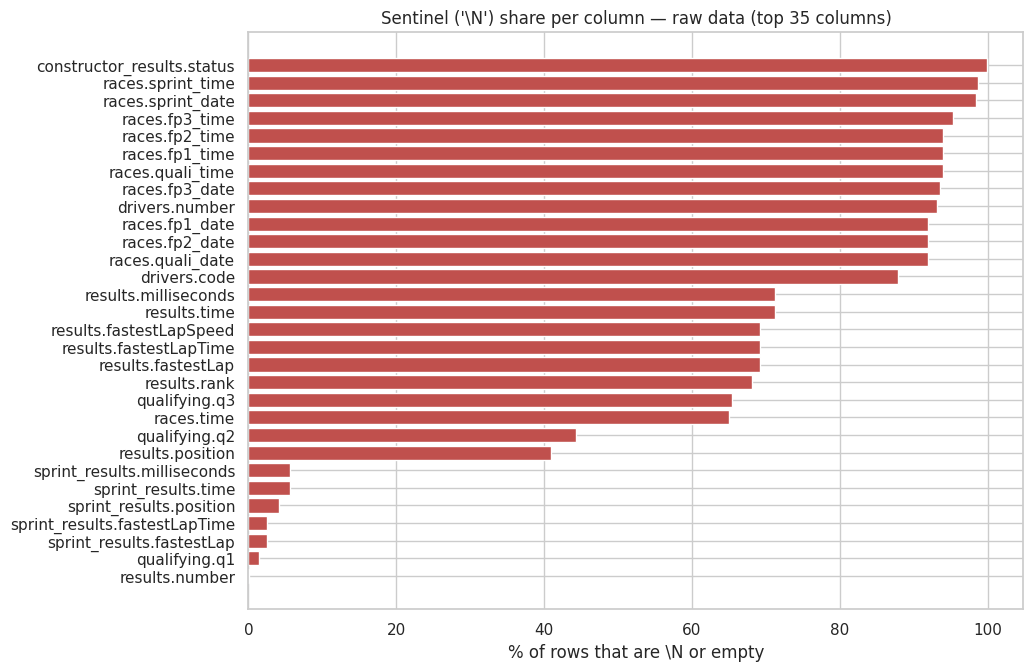

In [3]:
SENTINEL = "\\N"
sent_rows = []
for t, df in raw.items():
    for c in df.columns:
        n_sent = int((df[c] == SENTINEL).sum())
        n_empty = int((df[c].str.strip() == "").sum())
        if n_sent or n_empty:
            sent_rows.append({"table": t, "column": c, "n_sentinel": n_sent, "n_empty": n_empty,
                              "share": (n_sent + n_empty) / len(df)})
sentinels_before = pd.DataFrame(sent_rows).sort_values("share", ascending=False)
savetable(sentinels_before, "sentinels_before_cleaning")
print(f"{len(sentinels_before)} columns contain sentinels; {sentinels_before.n_sentinel.sum():,} \\N cells in total")

fig, ax = plt.subplots(figsize=(10, max(4, 0.25 * len(sentinels_before.head(35)))))
top = sentinels_before.head(35)
ax.barh(top.table + "." + top.column, top.share * 100, color="#c0504d")
ax.invert_yaxis()
ax.set_xlabel("% of rows that are \\N or empty")
ax.set_title("Sentinel ('\\N') share per column — raw data (top 35 columns)")
savefig(fig, "eda_raw_sentinels", "Share of placeholder values per column in the raw CSVs.")

A naive `pd.read_csv` cannot type columns that mix numbers and `\N`; they silently become text (`object`).
This is the evidence that sentinel handling has to come *before* typing.

In [4]:
naive_types = []
for t in ["results", "qualifying", "races", "drivers", "pit_stops"]:
    if t not in raw:
        continue
    naive = pd.read_csv(DATA_DIR / f"{t}.csv", nrows=50000)
    for c in naive.columns:
        if not pd.api.types.is_numeric_dtype(naive[c]):
            sample = raw[t][c][raw[t][c] != SENTINEL].head(200)
            numeric_like = pd.to_numeric(sample, errors="coerce").notna().mean() if len(sample) else 0
            naive_types.append({"table": t, "column": c, "naive dtype": str(naive[c].dtype),
                                "values numeric-like (excl. \\N)": f"{numeric_like:.0%}",
                                "example": sample.iloc[0] if len(sample) else ""})
naive_types = pd.DataFrame(naive_types)
naive_types

,table,column,naive dtype,values numeric-like (excl. \N),example
0,results,number,object,100%,22
1,results,position,object,100%,1
2,results,positionText,object,72%,1
3,results,time,object,68%,1:34:50.616
4,results,milliseconds,object,100%,5690616
5,results,fastestLap,object,100%,39
6,results,rank,object,100%,2
7,results,fastestLapTime,object,0%,1:27.452
8,results,fastestLapSpeed,object,100%,218.300
9,qualifying,q1,object,0%,1:26.572


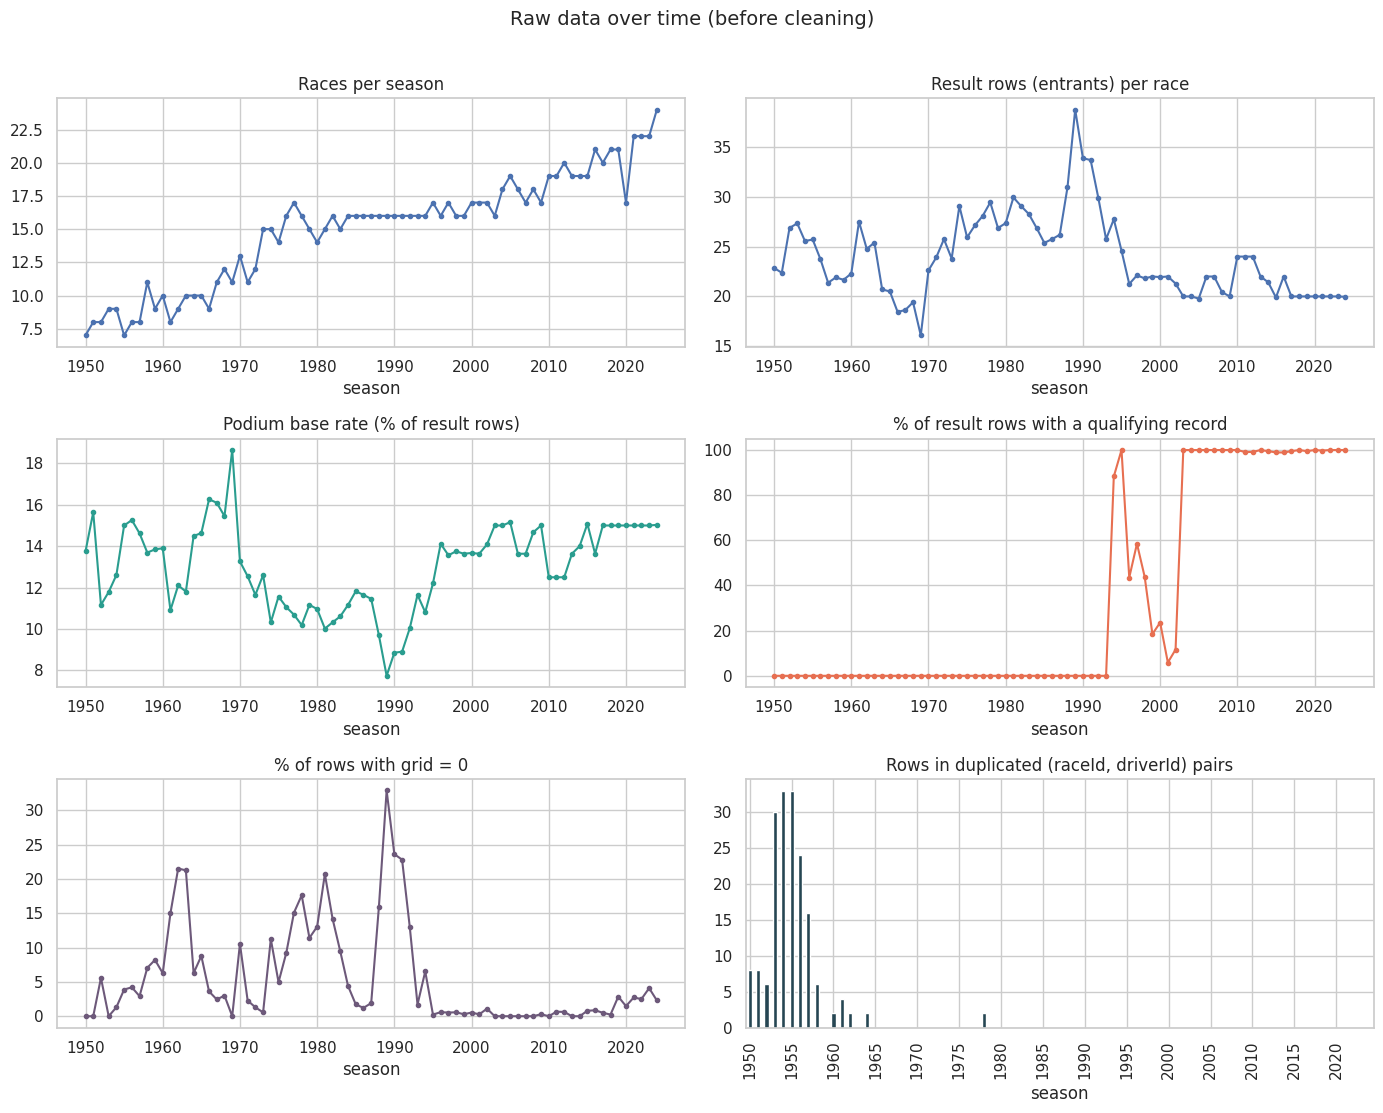

Qualifying data covers most rows only from 1994; before that the grid is the only start record.


,races,rows,podium_share,grid0,entrants_per_race,duplicate_rows,quali_coverage
year,,,,,,,
2017,20,400,0.150000,0.005000,20.000000,0.0,0.995000
2018,21,420,0.150000,0.002381,20.000000,0.0,1.000000
2019,21,420,0.150000,0.028571,20.000000,0.0,0.995238
2020,17,340,0.150000,0.014706,20.000000,0.0,1.000000
2021,22,440,0.150000,0.027273,20.000000,0.0,0.997727
2022,22,440,0.150000,0.025000,20.000000,0.0,1.000000
2023,22,440,0.150000,0.040909,20.000000,0.0,1.000000
2024,24,479,0.150313,0.022965,19.958333,0.0,1.000000


In [5]:
# Light, EDA-only conversions (the real cleaning is in section 2)
r_res = raw["results"].assign(**{c: pd.to_numeric(raw["results"][c], errors="coerce")
                                 for c in ["raceId", "driverId", "grid", "positionOrder", "statusId"]})
r_races = raw["races"].assign(raceId=pd.to_numeric(raw["races"].raceId), year=pd.to_numeric(raw["races"].year))
r = r_res.merge(r_races[["raceId", "year", "name"]], on="raceId", how="left")
r["podium"] = r.positionOrder <= 3
per_season = r.groupby("year").agg(races=("raceId", "nunique"), rows=("raceId", "size"),
                                   podium_share=("podium", "mean"), grid0=("grid", lambda s: (s == 0).mean()))
per_season["entrants_per_race"] = per_season.rows / per_season.races
dup_counts = r[r.duplicated(["raceId", "driverId"], keep=False)].groupby("year").size()
per_season["duplicate_rows"] = dup_counts.reindex(per_season.index).fillna(0)
q_keys = raw["qualifying"][["raceId", "driverId"]].apply(pd.to_numeric).drop_duplicates()
r = r.merge(q_keys.assign(has_q=True), on=["raceId", "driverId"], how="left")
per_season["quali_coverage"] = r.groupby("year").has_q.apply(lambda s: s.fillna(False).astype(bool).mean())

fig, axes = plt.subplots(3, 2, figsize=(14, 11))
per_season.races.plot(ax=axes[0, 0], marker=".", title="Races per season")
per_season.entrants_per_race.plot(ax=axes[0, 1], marker=".", title="Result rows (entrants) per race")
(per_season.podium_share * 100).plot(ax=axes[1, 0], marker=".", color="#2a9d8f",
                                     title="Podium base rate (% of result rows)")
(per_season.quali_coverage * 100).plot(ax=axes[1, 1], marker=".", color="#e76f51",
                                       title="% of result rows with a qualifying record")
(per_season.grid0 * 100).plot(ax=axes[2, 0], marker=".", color="#6d597a", title="% of rows with grid = 0")
per_season.duplicate_rows.plot(ax=axes[2, 1], kind="bar", color="#264653",
                               title="Rows in duplicated (raceId, driverId) pairs")
axes[2, 1].xaxis.set_major_locator(plt.MaxNLocator(15))
for ax in axes.flat:
    ax.set_xlabel("season")
fig.suptitle("Raw data over time (before cleaning)", y=1.01, fontsize=14)
fig.tight_layout()
savefig(fig, "eda_raw_seasons", "Season structure, podium base rate, qualifying coverage, grid 0 and "
        "duplicated driver-race rows in the raw data.")
first_q_year = int(per_season.index[per_season.quali_coverage > 0.5].min())
REPORT["first_quali_year"] = first_q_year
print(f"Qualifying data covers most rows only from {first_q_year}; before that the grid is the only start record.")
per_season.tail(8)

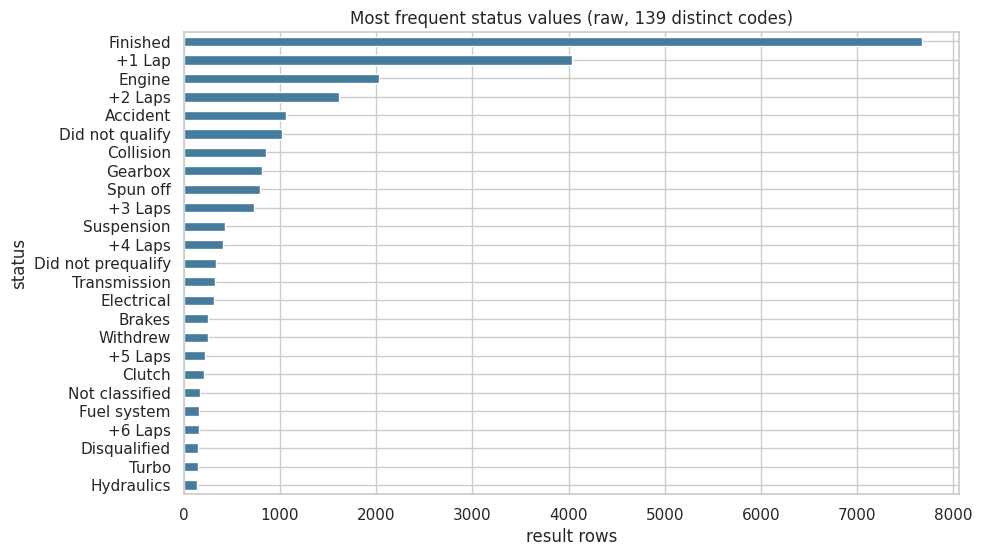

In [6]:
status_raw = r.merge(raw["status"].assign(statusId=pd.to_numeric(raw["status"].statusId)), on="statusId",
                     how="left")
top_status = status_raw.status.value_counts().head(25)
fig, ax = plt.subplots(figsize=(10, 6))
top_status.iloc[::-1].plot(kind="barh", ax=ax, color="#457b9d")
ax.set_title(f"Most frequent status values (raw, {raw['status'].shape[0]} distinct codes)")
ax.set_xlabel("result rows")
savefig(fig, "eda_raw_status", "Most common race-end status values.")

## 2. Data cleaning and auditing

### 2.1 Sentinels and semantic typing
* `\N` and empty strings → proper missing values (`<NA>` / `NaN`).
* IDs and counts → nullable integers; points, coordinates → floats.
* Dates → `datetime64`; clock times (`HH:MM:SS`) → `timedelta`.
* Lap/session/pit-stop durations (`"1:27.452"`, `"22.345"`, `"1:02:03.5"`) → **numeric seconds**.
* Every conversion is checked: a value that was present before typing but fails to parse is counted.

In [7]:
SCHEMA = {
    "circuits": {"int": ["circuitId"], "float": ["lat", "lng", "alt"]},
    "constructors": {"int": ["constructorId"]},
    "constructor_results": {"int": ["constructorResultsId", "raceId", "constructorId"], "float": ["points"]},
    "constructor_standings": {"int": ["constructorStandingsId", "raceId", "constructorId", "position", "wins"],
                              "float": ["points"]},
    "drivers": {"int": ["driverId", "number"], "date": ["dob"]},
    "driver_standings": {"int": ["driverStandingsId", "raceId", "driverId", "position", "wins"],
                         "float": ["points"]},
    "races": {"int": ["raceId", "year", "round", "circuitId"],
              "date": ["date", "fp1_date", "fp2_date", "fp3_date", "quali_date", "sprint_date"],
              "clock": ["time", "fp1_time", "fp2_time", "fp3_time", "quali_time", "sprint_time"]},
    "results": {"int": ["resultId", "raceId", "driverId", "constructorId", "number", "grid", "position",
                        "positionOrder", "laps", "milliseconds", "fastestLap", "rank", "statusId"],
                "float": ["points", "fastestLapSpeed"], "duration": ["fastestLapTime"]},
    "sprint_results": {"int": ["resultId", "raceId", "driverId", "constructorId", "number", "grid", "position",
                               "positionOrder", "laps", "milliseconds", "fastestLap", "statusId"],
                       "float": ["points"], "duration": ["fastestLapTime"]},
    "qualifying": {"int": ["qualifyId", "raceId", "driverId", "constructorId", "number", "position"],
                   "duration": ["q1", "q2", "q3"]},
    "lap_times": {"int": ["raceId", "driverId", "lap", "position", "milliseconds"], "duration": ["time"]},
    "pit_stops": {"int": ["raceId", "driverId", "stop", "lap", "milliseconds"], "duration": ["duration"],
                  "clock": ["time"]},
    "seasons": {"int": ["year"]},
    "status": {"int": ["statusId"]},
}


def duration_to_seconds(series):
    """'1:27.452' -> 87.452, '27.452' -> 27.452, '1:02:03.5' -> 3723.5; unparseable -> NaN."""
    def parse(v):
        if v is None or (isinstance(v, float) and np.isnan(v)) or v is pd.NA:
            return np.nan
        v = str(v).strip()
        if not re.fullmatch(r"\d+(:\d{1,2}){0,2}(\.\d+)?", v):
            return np.nan
        secs = 0.0
        for part in v.split(":"):
            secs = secs * 60 + float(part)
        return secs
    uniq = series.dropna().unique()
    mapping = {u: parse(u) for u in uniq}
    return series.map(mapping).astype(float)


def clean_table(name, df):
    df = df.copy()
    obj_cols = df.columns
    df[obj_cols] = df[obj_cols].replace({SENTINEL: np.nan, "": np.nan})
    df = df.apply(lambda s: s.str.strip() if pd.api.types.is_string_dtype(s) else s)
    failures = []
    spec = SCHEMA.get(name, {})
    for kind, cols in spec.items():
        for c in cols:
            if c not in df.columns:
                continue
            before = df[c].notna()
            if kind == "int":
                df[c] = pd.to_numeric(df[c], errors="coerce").astype("Int64")
            elif kind == "float":
                df[c] = pd.to_numeric(df[c], errors="coerce").astype(float)
            elif kind == "date":
                df[c] = pd.to_datetime(df[c], errors="coerce", format="%Y-%m-%d")
            elif kind == "clock":
                df[c] = pd.to_timedelta(df[c], errors="coerce")
            elif kind == "duration":
                df[c] = duration_to_seconds(df[c])
            failed = int((before & df[c].isna()).sum())
            failures.append({"table": name, "column": c, "type": kind, "non-missing": int(before.sum()),
                             "failed to parse": failed})
    return df, failures


clean, parse_log = {}, []
for t, df in raw.items():
    clean[t], f = clean_table(t, df)
    parse_log += f
parse_log = pd.DataFrame(parse_log)
savetable(parse_log, "typing_parse_log")
print("Columns with parse failures:")
display_cols = parse_log[parse_log["failed to parse"] > 0]
display_cols if len(display_cols) else print("  none — every non-missing value was converted")

Columns with parse failures:
  none — every non-missing value was converted


In [8]:
dtype_cmp = pd.DataFrame({
    "raw dtype": raw["results"].dtypes.astype(str),
    "clean dtype": clean["results"].dtypes.astype(str),
    "missing after cleaning": clean["results"].isna().sum(),
})
dtype_cmp

,raw dtype,clean dtype,missing after cleaning
resultId,object,Int64,0
raceId,object,Int64,0
driverId,object,Int64,0
constructorId,object,Int64,0
number,object,Int64,6
grid,object,Int64,0
position,object,Int64,10953
positionText,object,object,0
positionOrder,object,Int64,0
points,object,float64,0


### 2.2 Primary and foreign keys
Primary keys must be unique and non-null; every foreign key must exist in the table it points to.
Raw CSVs are never modified: orphan rows (if any) are dropped from the *clean copies* only and logged.

In [9]:
PK = {"circuits": ["circuitId"], "constructors": ["constructorId"], "drivers": ["driverId"], "races": ["raceId"],
      "status": ["statusId"], "seasons": ["year"], "results": ["resultId"], "sprint_results": ["resultId"],
      "qualifying": ["qualifyId"], "constructor_results": ["constructorResultsId"],
      "constructor_standings": ["constructorStandingsId"], "driver_standings": ["driverStandingsId"],
      "lap_times": ["raceId", "driverId", "lap"], "pit_stops": ["raceId", "driverId", "stop"]}
NATURAL_KEYS = {"results": ["raceId", "driverId"], "qualifying": ["raceId", "driverId"],
                "driver_standings": ["raceId", "driverId"], "constructor_standings": ["raceId", "constructorId"],
                "races": ["year", "round"], "sprint_results": ["raceId", "driverId"]}
pk_rows = []
for t, cols in {**PK, **{f"{k} (natural)": v for k, v in NATURAL_KEYS.items()}}.items():
    table = t.split(" ")[0]
    if table not in clean:
        continue
    df = clean[table]
    pk_rows.append({"table": t, "key": ", ".join(cols), "rows": len(df),
                    "null keys": int(df[cols].isna().any(axis=1).sum()),
                    "duplicate keys": int(df.duplicated(cols).sum())})
pk_audit = savetable(pd.DataFrame(pk_rows), "primary_key_audit")
pk_audit

,table,key,rows,null keys,duplicate keys
0,circuits,circuitId,77,0,0
1,constructors,constructorId,212,0,0
2,drivers,driverId,861,0,0
3,races,raceId,1125,0,0
4,status,statusId,139,0,0
5,seasons,year,75,0,0
6,results,resultId,26759,0,0
7,sprint_results,resultId,360,0,0
8,qualifying,qualifyId,10494,0,0
9,constructor_results,constructorResultsId,12625,0,0


In [10]:
FK = [("results", "raceId", "races"), ("results", "driverId", "drivers"), ("results", "constructorId", "constructors"),
      ("results", "statusId", "status"), ("qualifying", "raceId", "races"), ("qualifying", "driverId", "drivers"),
      ("qualifying", "constructorId", "constructors"), ("driver_standings", "raceId", "races"),
      ("driver_standings", "driverId", "drivers"), ("constructor_standings", "raceId", "races"),
      ("constructor_standings", "constructorId", "constructors"), ("constructor_results", "raceId", "races"),
      ("constructor_results", "constructorId", "constructors"), ("lap_times", "raceId", "races"),
      ("lap_times", "driverId", "drivers"), ("pit_stops", "raceId", "races"), ("pit_stops", "driverId", "drivers"),
      ("sprint_results", "raceId", "races"), ("sprint_results", "driverId", "drivers"),
      ("sprint_results", "constructorId", "constructors"), ("sprint_results", "statusId", "status"),
      ("races", "circuitId", "circuits"), ("races", "year", "seasons")]
fk_rows, cleaning_log = [], []
for child, col, parent in FK:
    if child not in clean or parent not in clean:
        continue
    parent_key = PK[parent][0]
    valid = clean[child][col].isna() | clean[child][col].isin(clean[parent][parent_key])
    fk_rows.append({"child": child, "foreign key": col, "parent": parent, "orphans": int((~valid).sum()),
                    "null FK": int(clean[child][col].isna().sum())})
    if (~valid).any():
        cleaning_log.append({"step": f"drop orphan {child}.{col}", "table": child, "rows removed": int((~valid).sum())})
        clean[child] = clean[child][valid].copy()
fk_audit = savetable(pd.DataFrame(fk_rows), "foreign_key_audit")
REPORT["fk_orphans"] = int(fk_audit.orphans.sum())
print(f"Foreign-key orphans found (and dropped from the clean copies): {REPORT['fk_orphans']}")
fk_audit

Foreign-key orphans found (and dropped from the clean copies): 0


,child,foreign key,parent,orphans,null FK
0,results,raceId,races,0,0
1,results,driverId,drivers,0,0
2,results,constructorId,constructors,0,0
3,results,statusId,status,0,0
4,qualifying,raceId,races,0,0
5,qualifying,driverId,drivers,0,0
6,qualifying,constructorId,constructors,0,0
7,driver_standings,raceId,races,0,0
8,driver_standings,driverId,drivers,0,0
9,constructor_standings,raceId,races,0,0


### 2.3 Grain: exactly one row per (raceId, driverId)

Duplicates come from **shared drives** (until 1957 a driver could take over a team-mate's car; each car he drove
gets a result row). Possible rules:
1. keep the row with the best `positionOrder` — uses the race outcome to pick the row (outcome-dependent choice);
2. **keep the car the driver started in** — the row with a non-zero grid; if several, the best (lowest) grid;
   if none, the best `positionOrder` (only reached for non-starters).

**We use rule 2**: the choice depends only on pre-race information (the grid), which is consistent with our
prediction cutoff, and the features we attach (grid, constructor) then describe the car the driver actually
started. Rule 1 is kept as a sensitivity check below.

In [11]:
res = clean["results"].merge(clean["races"][["raceId", "year", "name"]], on="raceId", how="left")
dup_mask = res.duplicated(["raceId", "driverId"], keep=False)
dups = res[dup_mask]
print(f"Duplicated (raceId, driverId) pairs: {dups.groupby(['raceId', 'driverId']).ngroups} "
      f"({len(dups)} rows), seasons {dups.year.min()}–{dups.year.max()}")
res["_started"] = res.grid.fillna(0) > 0
res["_grid_key"] = res.grid.where(res._started, 10_000)
rule2 = (res.sort_values(["raceId", "driverId", "_started", "_grid_key", "positionOrder"],
                         ascending=[True, True, False, True, True])
         .drop_duplicates(["raceId", "driverId"], keep="first"))
rule1 = res.sort_values(["raceId", "driverId", "positionOrder"]).drop_duplicates(["raceId", "driverId"])
cmp = rule2[["raceId", "driverId", "positionOrder"]].merge(
    rule1[["raceId", "driverId", "positionOrder"]], on=["raceId", "driverId"], suffixes=("_rule2", "_rule1"))
label_diff = int(((cmp.positionOrder_rule2 <= 3) != (cmp.positionOrder_rule1 <= 3)).sum())
REPORT["dup_pairs"] = int(dups.groupby(["raceId", "driverId"]).ngroups)
REPORT["dup_rows_removed"] = len(res) - len(rule2)
REPORT["dup_label_diff"] = label_diff
print(f"Rows removed by the grain rule: {REPORT['dup_rows_removed']}. "
      f"Podium labels that would differ under rule 1: {label_diff} (all in training seasons).")
cleaning_log.append({"step": "grain: one row per (raceId, driverId), keep starting car", "table": "results",
                     "rows removed": REPORT["dup_rows_removed"]})
results_g = rule2.drop(columns=["_started", "_grid_key"])
assert not results_g.duplicated(["raceId", "driverId"]).any()
dups.sort_values(["raceId", "driverId"])[["year", "name", "raceId", "driverId", "constructorId", "grid",
                                          "positionOrder", "points"]].head(10)

Duplicated (raceId, driverId) pairs: 85 (176 rows), seasons 1950–1978
Rows removed by the grain rule: 91. Podium labels that would differ under rule 1: 17 (all in training seasons).


,year,name,raceId,driverId,constructorId,grid,positionOrder,points
13188,1978,Italian Grand Prix,540,229,54,0,26,0.0
13191,1978,Italian Grand Prix,540,229,57,0,29,0.0
17362,1964,United States Grand Prix,717,373,172,1,7,0.0
24298,1964,United States Grand Prix,717,373,172,1,12,0.0
17740,1962,British Grand Prix,733,465,172,0,22,0.0
17743,1962,British Grand Prix,733,465,97,0,25,0.0
17961,1961,British Grand Prix,742,475,102,20,19,0.0
17963,1961,British Grand Prix,742,475,172,5,21,0.0
18062,1961,United States Grand Prix,745,418,172,11,17,0.0
24297,1961,United States Grand Prix,745,418,172,15,11,0.0


### 2.4 Scope of the modelling population
* **Indianapolis 500 (1950–1960)** — counted for the championship but a separate American oval event that F1
  regulars almost never entered. It distorts home-race analysis and grid structure → excluded.
* **Did not (pre-)qualify / Withdrew / 107% rule** — these entrants never take the start. At our cutoff (after
  qualifying) this is already known, so a podium prediction for them is meaningless → excluded.
* Grid `0` with a real start = pit-lane start → kept (handled as a feature, see section 5).

In [12]:
status_map = clean["status"].set_index("statusId").status
results_g["status"] = results_g.statusId.map(status_map)
NON_START_RE = re.compile(r"did not (pre)?qualify|withdrew|107%|did not start|not started", re.I)
is_indy = results_g.name.str.contains("Indianapolis 500", case=False, na=False)
is_nonstart = results_g.status.fillna("").str.contains(NON_START_RE)
cleaning_log += [{"step": "exclude Indianapolis 500 (1950-1960)", "table": "results",
                  "rows removed": int(is_indy.sum())},
                 {"step": "exclude non-starters (DNQ/DNPQ/withdrew)", "table": "results",
                  "rows removed": int((is_nonstart & ~is_indy).sum())}]
base = results_g[~is_indy & ~is_nonstart].copy()
base = base.merge(clean["races"][["raceId", "round", "circuitId", "date"]], on="raceId", how="left")
base["podium"] = (base.positionOrder <= 3).astype(int)
cleaning_log = savetable(pd.DataFrame(cleaning_log), "cleaning_log")
REPORT["n_rows_model_base"] = len(base)
print(f"Results rows: raw {len(raw['results']):,} → modelling population {len(base):,}")
cleaning_log

Results rows: raw 26,759 → modelling population 24,677


,step,table,rows removed
0,"grain: one row per (raceId, driverId), keep st...",results,91
1,exclude Indianapolis 500 (1950-1960),results,381
2,exclude non-starters (DNQ/DNPQ/withdrew),results,1610


## 3. EDA after cleaning — impact of the cleaning

'\N' strings left in the clean tables: 0


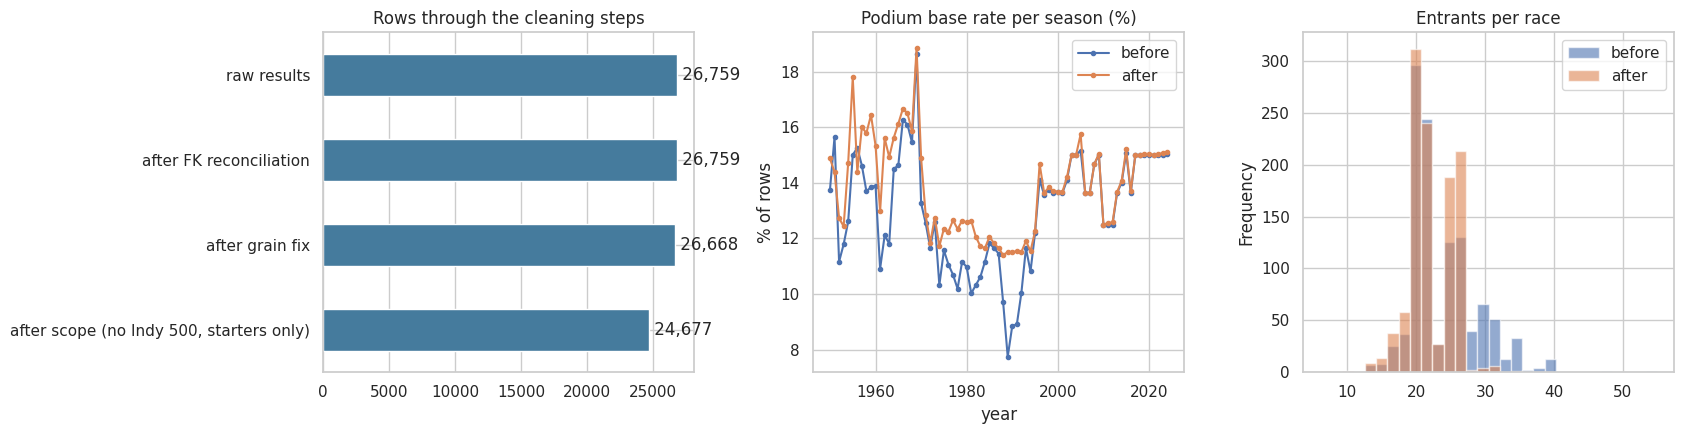

raw results                                 26759
after FK reconciliation                     26759
after grain fix                             26668
after scope (no Indy 500, starters only)    24677
dtype: int64

In [13]:
remaining_sentinels = sum(int((df.astype(str) == SENTINEL).sum().sum()) for df in clean.values())
print(f"'\\N' strings left in the clean tables: {remaining_sentinels}")
funnel = pd.Series({"raw results": len(raw["results"]),
                    "after FK reconciliation": len(clean["results"]),
                    "after grain fix": len(results_g),
                    "after scope (no Indy 500, starters only)": len(base)})
before_after = pd.DataFrame({
    "before": r.groupby("year").podium.mean(),
    "after": base.groupby("year").podium.mean()})

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
funnel.plot(kind="barh", ax=axes[0], color="#457b9d")
axes[0].invert_yaxis()
axes[0].set_title("Rows through the cleaning steps")
for i, v in enumerate(funnel):
    axes[0].text(v, i, f" {v:,}", va="center")
(before_after * 100).plot(ax=axes[1], marker=".")
axes[1].set_title("Podium base rate per season (%)")
axes[1].set_ylabel("% of rows")
entr = pd.DataFrame({"before": r.groupby("raceId").size(), "after": base.groupby("raceId").size()})
entr.plot(kind="hist", bins=30, alpha=0.6, ax=axes[2])
axes[2].set_title("Entrants per race")
fig.tight_layout()
savefig(fig, "eda_clean_impact", "Effect of cleaning on row counts, podium base rate and field size. Removing "
        "non-starters raises the base rate in the over-subscribed 1980s-90s.")
funnel

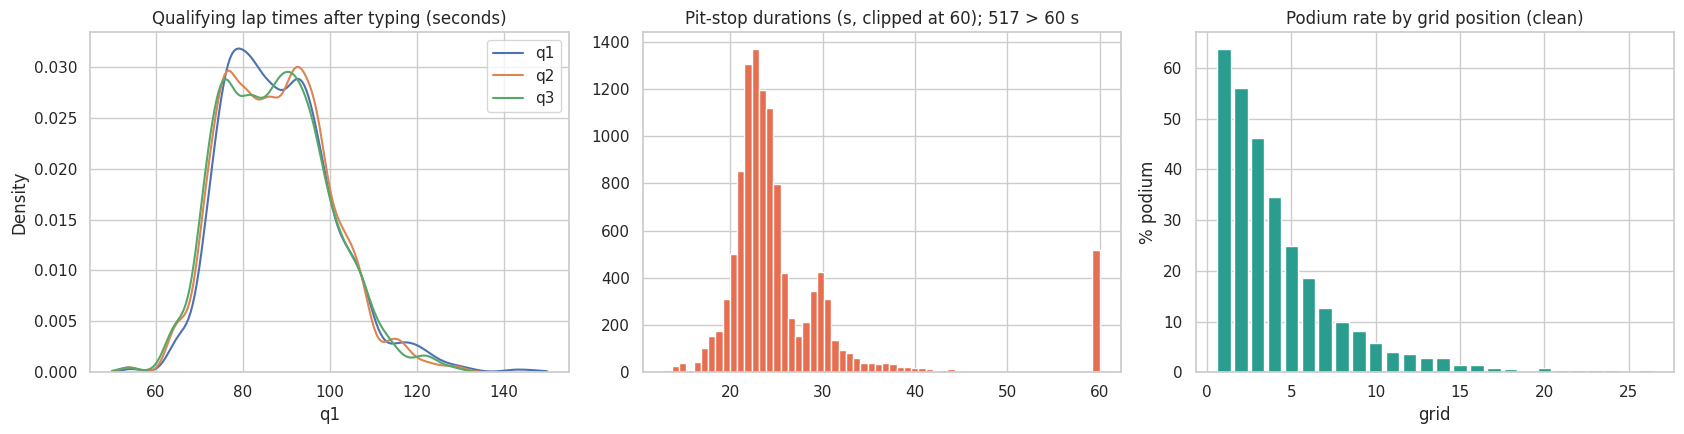

In [14]:
q = clean["qualifying"]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for c in ["q1", "q2", "q3"]:
    sns.kdeplot(q[c].dropna(), ax=axes[0], label=c, clip=(50, 150))
axes[0].set_title("Qualifying lap times after typing (seconds)")
axes[0].legend()
pit = clean["pit_stops"].duration.dropna()
axes[1].hist(pit.clip(upper=60), bins=60, color="#e76f51")
axes[1].set_title(f"Pit-stop durations (s, clipped at 60); {int((pit > 60).sum())} > 60 s")
grid_rate = base[base.grid > 0].groupby("grid").podium.agg(["mean", "size"])
grid_rate = grid_rate[grid_rate["size"] >= 30]
axes[2].bar(grid_rate.index, grid_rate["mean"] * 100, color="#2a9d8f")
axes[2].set_title("Podium rate by grid position (clean)")
axes[2].set_xlabel("grid")
axes[2].set_ylabel("% podium")
fig.tight_layout()
savefig(fig, "eda_clean_distributions", "Durations are now numeric. Pit stops longer than 60 s are red-flag "
        "periods recorded as stops; pit data is post-race and never used as a feature. Podium rate falls steeply "
        "with grid position.")

## 4. Data-engineering questions

Shared joins: `results` (grain fixed) ⟶ `races` (year, circuit, date) ⟶ `circuits` (name, country);
`qualifying` gives the qualifying position; `drivers` gives nationality; `status` gives why a race ended;
`constructors` gives team names. Grain for all three questions: one row per driver per race start.

In [15]:
dq = (base.merge(clean["circuits"][["circuitId", "name", "country"]].rename(columns={"name": "circuit"}),
                 on="circuitId", how="left")
      .merge(clean["qualifying"].drop_duplicates(["raceId", "driverId"])[["raceId", "driverId", "position"]]
             .rename(columns={"position": "quali_pos"}), on=["raceId", "driverId"], how="left")
      .merge(clean["drivers"][["driverId", "nationality"]], on="driverId", how="left")
      .merge(clean["constructors"][["constructorId", "name"]].rename(columns={"name": "constructor"}),
             on="constructorId", how="left"))


def wilson(k, n, z=1.96):
    p = k / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return centre - half, centre + half

### Q1. Which circuits convert a front-row start into a podium most often, and does the ranking change with the
2014 hybrid era?

* **Front row by grid** = grid 1 or 2 (actual start, after penalties). **Front row by qualifying** = qualifying
  position 1 or 2 (before penalties). The two differ whenever a penalty moves a driver.
* Periods: **1994–2013** (pre-hybrid; starts in 1994 so both definitions use years where qualifying data
  exists) vs **2014–2024** (hybrid + ground-effect).
* Conversion = podiums / front-row starts. Circuits need ≥ `MIN_FR` front-row starts in *both* periods.

In [16]:
MIN_FR = 8
q1 = dq[dq.year >= 1994].copy()
q1["period"] = np.where(q1.year >= 2014, "2014–2024", "1994–2013")
q1_tables = {}
for basis, col in [("grid", "grid"), ("qualifying", "quali_pos")]:
    fr = q1[q1[col].isin([1, 2])]
    t = fr.groupby(["circuit", "period"]).podium.agg(podiums="sum", starts="size").reset_index()
    t["rate"] = t.podiums / t.starts
    wide = t.pivot(index="circuit", columns="period", values=["rate", "starts"])
    wide.columns = [f"{a}_{b}" for a, b in wide.columns]
    wide = wide.dropna()
    wide = wide[(wide["starts_1994–2013"] >= MIN_FR) & (wide["starts_2014–2024"] >= MIN_FR)]
    wide["rank_1994–2013"] = wide["rate_1994–2013"].rank(ascending=False, method="min")
    wide["rank_2014–2024"] = wide["rate_2014–2024"].rank(ascending=False, method="min")
    q1_tables[basis] = wide.sort_values("rate_2014–2024", ascending=False)
    savetable(q1_tables[basis], f"q1_front_row_conversion_{basis}")

overall = q1[q1.grid.isin([1, 2])].groupby("period").podium.mean()
rho, p_rho = stats.spearmanr(q1_tables["grid"]["rate_1994–2013"], q1_tables["grid"]["rate_2014–2024"]) \
    if len(q1_tables["grid"]) > 2 else (np.nan, np.nan)
pen = q1.dropna(subset=["quali_pos"])
pen_fr = pen[pen.quali_pos.isin([1, 2]) & ~pen.grid.isin([1, 2])]
REPORT.update(q1_overall=overall.to_dict(), q1_rho=rho, q1_p=p_rho, q1_n_circuits=len(q1_tables["grid"]),
              q1_penalised=len(pen_fr), q1_pen_rate=pen_fr.podium.mean() if len(pen_fr) else np.nan,
              q1_top_pre=q1_tables["grid"].sort_values("rate_1994–2013", ascending=False).head(5).index.tolist(),
              q1_top_post=q1_tables["grid"].head(5).index.tolist())
print(f"Front-row (grid) conversion overall: {overall.round(3).to_dict()}")
print(f"Spearman rank correlation of circuit conversion between periods: rho={rho:.2f} (p={p_rho:.3f}), "
      f"{len(q1_tables['grid'])} circuits")
print(f"Qualified on the front row but started further back (penalties): {len(pen_fr)} cases, podium rate "
      f"{REPORT['q1_pen_rate']:.1%}")
q1_tables["grid"].head(10)

Front-row (grid) conversion overall: {'1994–2013': 0.644, '2014–2024': 0.76}
Spearman rank correlation of circuit conversion between periods: rho=-0.21 (p=0.414), 17 circuits
Qualified on the front row but started further back (penalties): 38 cases, podium rate 28.9%


,rate_1994–2013,rate_2014–2024,starts_1994–2013,starts_2014–2024,rank_1994–2013,rank_2014–2024
circuit,,,,,,
Suzuka Circuit,0.750000,0.888889,36.0,18.0,1.0,1.0
Yas Marina Circuit,0.600000,0.863636,10.0,22.0,12.0,2.0
Circuit de Monaco,0.650000,0.850000,40.0,20.0,6.0,3.0
Circuit de Spa-Francorchamps,0.500000,0.818182,36.0,22.0,17.0,4.0
Circuit de Barcelona-Catalunya,0.650000,0.818182,40.0,22.0,6.0,4.0
Autódromo José Carlos Pace,0.550000,0.789474,40.0,19.0,16.0,6.0
Shanghai International Circuit,0.650000,0.785714,20.0,14.0,6.0,7.0
Circuit Gilles Villeneuve,0.578947,0.777778,38.0,18.0,14.0,8.0
Autodromo Enzo e Dino Ferrari,0.653846,0.750000,26.0,8.0,5.0,9.0


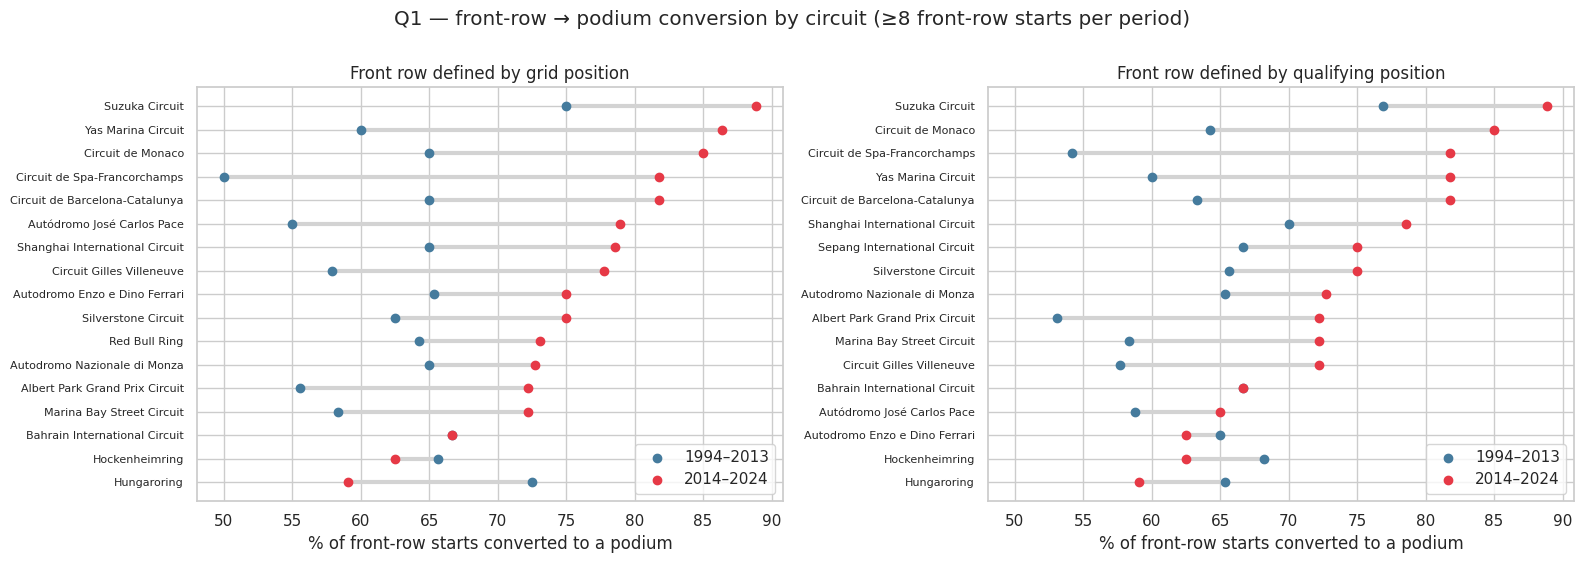

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(16, max(5, 0.33 * len(q1_tables["grid"]))), sharex=True)
for ax, basis in zip(axes, ["grid", "qualifying"]):
    w = q1_tables[basis].sort_values("rate_2014–2024")
    y = np.arange(len(w))
    ax.hlines(y, w["rate_1994–2013"] * 100, w["rate_2014–2024"] * 100, color="lightgrey", lw=3)
    ax.scatter(w["rate_1994–2013"] * 100, y, label="1994–2013", color="#457b9d", zorder=3)
    ax.scatter(w["rate_2014–2024"] * 100, y, label="2014–2024", color="#e63946", zorder=3)
    ax.set_yticks(y)
    ax.set_yticklabels(w.index, fontsize=8)
    ax.set_xlabel("% of front-row starts converted to a podium")
    ax.set_title(f"Front row defined by {basis} position")
    ax.legend(loc="lower right")
fig.suptitle(f"Q1 — front-row → podium conversion by circuit (≥{MIN_FR} front-row starts per period)", y=1.0)
fig.tight_layout()
savefig(fig, "q1_front_row_conversion", "Q1: front-row-to-podium conversion per circuit before and since the "
        "2014 hybrid era, by grid and by qualifying definition.")

**Answer — Q1.** From 1994–2013, **64.4%** of front-row starts (grid P1–P2) ended on the podium; from
2014–2024 this rose to **76.0%**. Suzuka is first in both periods (75.0% → 88.9%). Since 2014 the top five are
Suzuka, Yas Marina, Monaco, Spa-Francorchamps and Barcelona; before 2014 they were Suzuka, Hungaroring, Bahrain,
Hockenheimring and Imola. **The ranking changes a lot with the hybrid era:** across the 17 circuits with at least
8 front-row starts in both periods, the Spearman rank correlation is **ρ = −0.21 (p = 0.414)**, so a circuit's
pre-2014 rank says almost nothing about its hybrid-era rank. **Grid vs qualifying:** 38 drivers qualified on the
front row but started further back because of penalties; only **28.9%** of them reached the podium, which is why
we use the grid (actual start) as the main definition and show the qualifying definition next to it.

* **Grain:** one row per driver per race start (results → races → circuits, plus qualifying for the
  qualifying-based definition).
* **Missingness:** qualifying data covers most rows only from 1994, so both periods start in 1994. Circuits with
  fewer than 8 front-row starts in a period are left out because the rates would be too noisy.
* **Pre-race cutoff:** grid and qualifying position are both fixed before the start, so both definitions use
  only pre-race information.

*Numbers from the full Kaggle run (Version 1, 17 Oct 2026). Re-check them if the code or data change.*

### Q2. Do drivers podium more often at home, after controlling for starting position?

* Home race = the circuit's country equals the country of the driver's nationality (mapping below; nationalities
  without a matching circuit country are never "home").
* Population: race starts (grid > 0), Indianapolis 500 excluded (section 2.4).
* Control: stratify by grid band (1, 2–3, 4–6, 7–10, 11+) and pool the strata with the **Cochran–Mantel–Haenszel**
  odds ratio (home vs away within the same grid band) and its 95% CI.

In [18]:
NAT_TO_COUNTRY = {
    "British": ["UK", "United Kingdom"], "German": ["Germany"], "East German": ["Germany"], "Italian": ["Italy"],
    "French": ["France"], "American": ["USA", "United States"], "American-Italian": ["USA", "United States"],
    "Brazilian": ["Brazil"], "Spanish": ["Spain"], "Finnish": ["Finland"], "Australian": ["Australia"],
    "Dutch": ["Netherlands"], "Japanese": ["Japan"], "Mexican": ["Mexico"], "Canadian": ["Canada"],
    "Belgian": ["Belgium"], "Austrian": ["Austria"], "Monegasque": ["Monaco"], "Argentine": ["Argentina"],
    "Argentine-Italian": ["Argentina"], "Argentinian": ["Argentina"], "Swiss": ["Switzerland"],
    "Swedish": ["Sweden"], "New Zealander": ["New Zealand"], "South African": ["South Africa"],
    "Portuguese": ["Portugal"], "Hungarian": ["Hungary"], "Malaysian": ["Malaysia"], "Russian": ["Russia"],
    "Chinese": ["China"], "Indian": ["India"], "Thai": ["Thailand"], "Danish": ["Denmark"], "Polish": ["Poland"],
    "Venezuelan": ["Venezuela"], "Colombian": ["Colombia"], "Irish": ["Ireland"], "Czech": ["Czech Republic"],
    "Uruguayan": ["Uruguay"], "Chilean": ["Chile"], "Indonesian": ["Indonesia"], "Saudi": ["Saudi Arabia"],
    "Emirati": ["UAE"], "Bahraini": ["Bahrain"], "Azerbaijani": ["Azerbaijan"], "Turkish": ["Turkey"],
    "Korean": ["Korea"], "Moroccan": ["Morocco"], "Singaporean": ["Singapore"], "Qatari": ["Qatar"],
    "Rhodesian": ["Zimbabwe"], "Liechtensteiner": ["Liechtenstein"],
}
circuit_countries = set(clean["circuits"].country.dropna())
nat_audit = pd.DataFrame({"nationality": sorted(dq.nationality.dropna().unique())})
nat_audit["home countries"] = nat_audit.nationality.map(lambda n: NAT_TO_COUNTRY.get(n, []))
nat_audit["has F1 circuit"] = nat_audit["home countries"].map(lambda cs: any(c in circuit_countries for c in cs))
unmapped = nat_audit[nat_audit["home countries"].map(len) == 0].nationality.tolist()
print("Nationalities without a mapping (treated as never home):", unmapped or "none")

dq["home"] = [c in NAT_TO_COUNTRY.get(n, []) for n, c in zip(dq.nationality, dq.country)]
q2 = dq[dq.grid > 0].copy()
q2["grid_band"] = pd.cut(q2.grid, [0, 1, 3, 6, 10, 100], labels=["P1", "P2-3", "P4-6", "P7-10", "P11+"])


def mantel_haenszel(df, strata="grid_band", exposure="home", outcome="podium"):
    rows, R, S = [], [], []
    num_chi, var_chi, PR, PS_QR, QS = 0, 0, 0, 0, 0
    for k, g in df.groupby(strata, observed=True):
        a = int(((g[exposure]) & (g[outcome] == 1)).sum()); b = int(((g[exposure]) & (g[outcome] == 0)).sum())
        c = int(((~g[exposure]) & (g[outcome] == 1)).sum()); d = int(((~g[exposure]) & (g[outcome] == 0)).sum())
        n = a + b + c + d
        if n < 2 or (a + b) == 0 or (c + d) == 0:
            continue
        Ri, Si = a * d / n, b * c / n
        Pi, Qi = (a + d) / n, (b + c) / n
        R.append(Ri); S.append(Si)
        PR += Pi * Ri; PS_QR += Pi * Si + Qi * Ri; QS += Qi * Si
        num_chi += a - (a + b) * (a + c) / n
        var_chi += (a + b) * (c + d) * (a + c) * (b + d) / (n * n * (n - 1))
        rows.append({"grid band": k, "home starts": a + b, "home podium %": 100 * a / (a + b),
                     "away starts": c + d, "away podium %": 100 * c / (c + d),
                     "stratum OR": (a * d) / (b * c) if b * c else np.nan})
    sR, sS = sum(R), sum(S)
    or_mh = sR / sS
    se = np.sqrt(PR / (2 * sR ** 2) + PS_QR / (2 * sR * sS) + QS / (2 * sS ** 2))
    chi2 = (abs(num_chi) - 0.5) ** 2 / var_chi
    return pd.DataFrame(rows), or_mh, (or_mh * np.exp(-1.96 * se), or_mh * np.exp(1.96 * se)), stats.chi2.sf(chi2, 1)


q2_strata, or_mh, or_ci, p_mh = mantel_haenszel(q2)
crude = pd.crosstab(q2.home, q2.podium)
or_crude = (crude.loc[True, 1] * crude.loc[False, 0]) / (crude.loc[True, 0] * crude.loc[False, 1])
REPORT.update(q2_or_mh=or_mh, q2_ci=or_ci, q2_p=p_mh, q2_or_crude=or_crude, q2_n_home=int(q2.home.sum()),
              q2_n=len(q2), q2_home_rate=q2[q2.home].podium.mean(), q2_away_rate=q2[~q2.home].podium.mean(),
              q2_home_grid=q2[q2.home].grid.mean(), q2_away_grid=q2[~q2.home].grid.mean())
savetable(q2_strata, "q2_home_by_grid_band")
print(f"Home starts: {REPORT['q2_n_home']:,} of {len(q2):,}. Crude podium rate home {REPORT['q2_home_rate']:.1%} vs "
      f"away {REPORT['q2_away_rate']:.1%} (crude OR {or_crude:.2f}).")
print(f"Mean grid: home {REPORT['q2_home_grid']:.1f} vs away {REPORT['q2_away_grid']:.1f}")
print(f"Grid-adjusted Mantel–Haenszel OR = {or_mh:.2f} (95% CI {or_ci[0]:.2f}–{or_ci[1]:.2f}), p = {p_mh:.3g}")
q2_strata.round(2)

Nationalities without a mapping (treated as never home): none
Home starts: 1,932 of 24,549. Crude podium rate home 11.6% vs away 13.8% (crude OR 0.82).
Mean grid: home 12.7 vs away 11.7
Grid-adjusted Mantel–Haenszel OR = 0.91 (95% CI 0.76–1.08), p = 0.302


,grid band,home starts,home podium %,away starts,away podium %,stratum OR
0,P1,84,58.33,1039,64.29,0.78
1,P2-3,147,53.74,2074,50.96,1.12
2,P4-6,226,26.55,3109,26.05,1.03
3,P7-10,334,7.19,4095,9.26,0.76
4,P11+,1141,1.05,12300,1.66,0.63


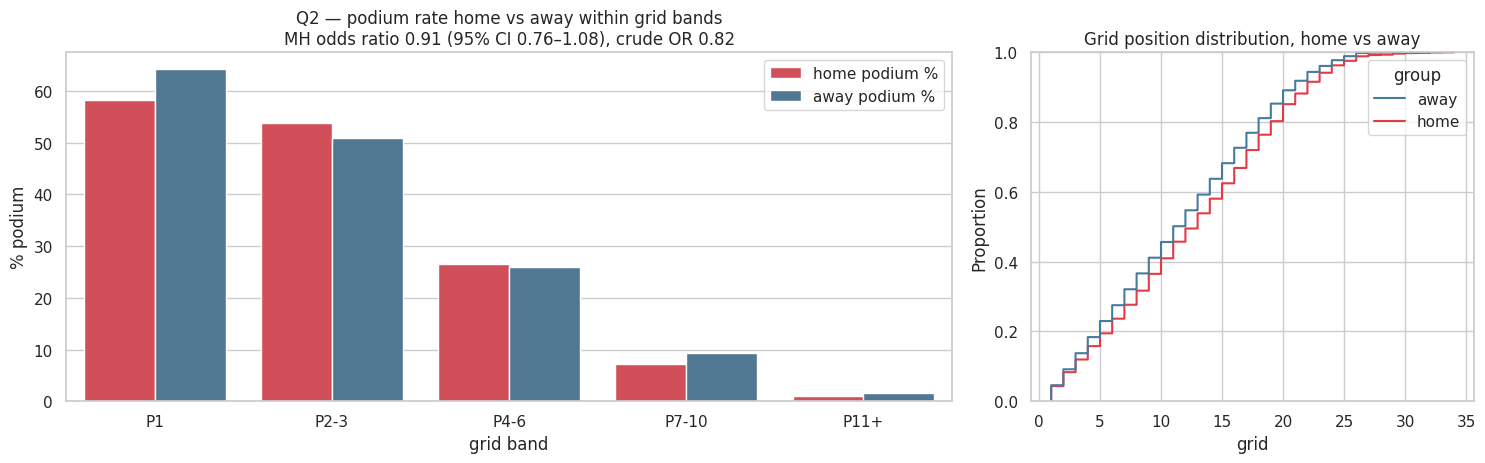

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [2, 1]})
m = q2_strata.melt(id_vars="grid band", value_vars=["home podium %", "away podium %"], var_name="", value_name="%")
sns.barplot(data=m, x="grid band", y="%", hue="", ax=axes[0], palette=["#e63946", "#457b9d"])
axes[0].set_title(f"Q2 — podium rate home vs away within grid bands\nMH odds ratio {or_mh:.2f} "
                  f"(95% CI {or_ci[0]:.2f}–{or_ci[1]:.2f}), crude OR {or_crude:.2f}")
axes[0].set_ylabel("% podium")
sns.ecdfplot(data=q2.assign(group=np.where(q2.home, "home", "away")), x="grid", hue="group", ax=axes[1],
             palette={"home": "#e63946", "away": "#457b9d"})
axes[1].set_title("Grid position distribution, home vs away")
fig.tight_layout()
savefig(fig, "q2_home_advantage", "Q2: podium rate at home vs away inside each grid band, with the pooled "
        "Mantel-Haenszel odds ratio; right: whether home drivers start further forward.")

**Answer — Q2. No detectable home advantage.** Without any control, home drivers look *worse*: podium rate
**11.6% at home vs 13.8% away** (crude odds ratio 0.82). Part of this is the start position: home drivers start
further back on average (grid 12.7 vs 11.7), so the crude comparison is unfair. After comparing drivers inside the same grid band (P1, P2–3, P4–6, P7–10, P11+), the pooled
**Mantel–Haenszel odds ratio is 0.91 (95% CI 0.76–1.08, p = 0.302)**. The interval includes 1, so once
starting position is controlled for, racing at home neither raises nor lowers the podium chance in a way we can
detect.

* **Grain:** one row per driver per race start (24,549 starts, 1,932 at home); results → races → circuits
  (country) and results → drivers (nationality).
* **Missingness:** every nationality was mapped (no unmapped nationalities). Drivers whose country has no
  circuit can never be "home". The Indianapolis 500 is excluded.
* **Pre-race cutoff:** grid, nationality and circuit country are all known before the start.

*Numbers from the full Kaggle run (Version 1, 17 Oct 2026). Re-check them if the code or data change.*

### Q3. Which constructors have the highest mechanical-retirement rate in 2014–2021 vs 2022–2024?

**Definition.** Rate = mechanical retirements / race starts of the constructor in the period. A mechanical
retirement is a start that ended because a car component failed — *not* crashes/contact, driver errors,
illness, punctures/debris, pit-crew errors (wheel nut), fuel strategy, or regulation decisions
(disqualified, excluded). The full status → category mapping used is printed below so it can be audited.

In [20]:
FINISHED_RE = re.compile(r"^(finished|\+\d+ laps?)$", re.I)
MECHANICAL = {
    "engine", "gearbox", "transmission", "clutch", "hydraulics", "electrical", "radiator", "suspension", "brakes",
    "differential", "overheating", "mechanical", "driveshaft", "fuel pressure", "water pressure", "wheel",
    "throttle", "steering", "technical", "electronics", "heat shield fire", "exhaust", "oil leak", "wheel rim",
    "water leak", "fuel pump", "track rod", "oil pressure", "engine fire", "pneumatics", "rear wing",
    "wheel bearing", "fuel system", "oil line", "power loss", "vibrations", "drivetrain", "ignition", "chassis",
    "battery", "halfshaft", "crankshaft", "alternator", "oil pump", "fuel leak", "injection", "distributor",
    "turbo", "cv joint", "water pump", "spark plugs", "fuel pipe", "oil pipe", "axle", "water pipe", "magneto",
    "supercharger", "power unit", "ers", "brake duct", "undertray", "cooling system", "launch control",
    "engine misfire", "front wing", "fire", "handling", "seat", "driver seat", "safety belt", "refuelling"}
# Ambiguous codes and where they went (justification for the report):
#   'front wing'/'rear wing'/'handling'/'seat' -> component failures; 'refuelling' -> refuelling-rig/valve failure
#   'puncture'/'tyre'/'debris'/'damage'/'collision damage' -> usually caused by contact -> accident/damage
ACCIDENT_DRIVER = {"accident", "collision", "spun off", "collision damage", "damage", "debris", "fatal accident",
                   "stalled", "physical", "injured", "injury", "eye injury", "illness", "driver unwell", "puncture",
                   "tyre", "tyre puncture", "broken wing", "out of fuel", "fuel", "wheel nut", "retired",
                   "not restarted", "fuel rig", "safety", "safety concerns"}
REGULATION = {"disqualified", "excluded", "underweight", "107% rule", "not classified"}


def status_group(s):
    s0 = str(s).strip().lower()
    if FINISHED_RE.match(s0):
        return "finished"
    if s0 in MECHANICAL:
        return "mechanical"
    if s0 in ACCIDENT_DRIVER:
        return "accident / driver / other"
    if s0 in REGULATION:
        return "regulation / not classified"
    if re.search(r"engine|gearbox|hydraul|electr|brake|suspension|power|turbo|fuel|oil|water|leak|pump", s0):
        return "mechanical"
    return "accident / driver / other"


dq["status_group"] = dq.status.map(status_group)
q3 = dq[dq.year.between(2014, 2024)].copy()
q3["period"] = np.where(q3.year <= 2021, "2014–2021", "2022–2024")
q3["mech"] = (q3.status_group == "mechanical").astype(int)
mapping_used = (q3.groupby(["status_group", "status"]).size().rename("starts").reset_index()
                .sort_values(["status_group", "starts"], ascending=[True, False]))
savetable(mapping_used, "q3_status_mapping")
MIN_STARTS = 20
q3t = (q3.groupby(["period", "constructor"]).agg(starts=("mech", "size"), mech=("mech", "sum")).reset_index()
       .query("starts >= @MIN_STARTS"))
q3t["rate"] = q3t.mech / q3t.starts
q3t[["ci_low", "ci_high"]] = np.array([wilson(k, n) for k, n in zip(q3t.mech, q3t.starts)])
q3t = q3t.sort_values(["period", "rate"], ascending=[True, False])
savetable(q3t, "q3_mechanical_retirement_rates")
REPORT["q3_overall"] = q3.groupby("period").mech.mean().to_dict()
REPORT["q3_top"] = {p: g.head(3)[["constructor", "rate", "starts"]].values.tolist() for p, g in q3t.groupby("period")}
print("Overall mechanical-retirement rate:", {k: f"{v:.1%}" for k, v in REPORT["q3_overall"].items()})
mapping_used

Overall mechanical-retirement rate: {'2014–2021': '9.7%', '2022–2024': '6.1%'}


,status_group,status,starts
1,accident / driver / other,Collision,150
0,accident / driver / other,Accident,85
2,accident / driver / other,Collision damage,59
8,accident / driver / other,Retired,50
9,accident / driver / other,Spun off,11
...,...,...,...
49,mechanical,Seat,1
50,mechanical,Spark plugs,1
61,mechanical,Water pump,1
63,regulation / not classified,Disqualified,11


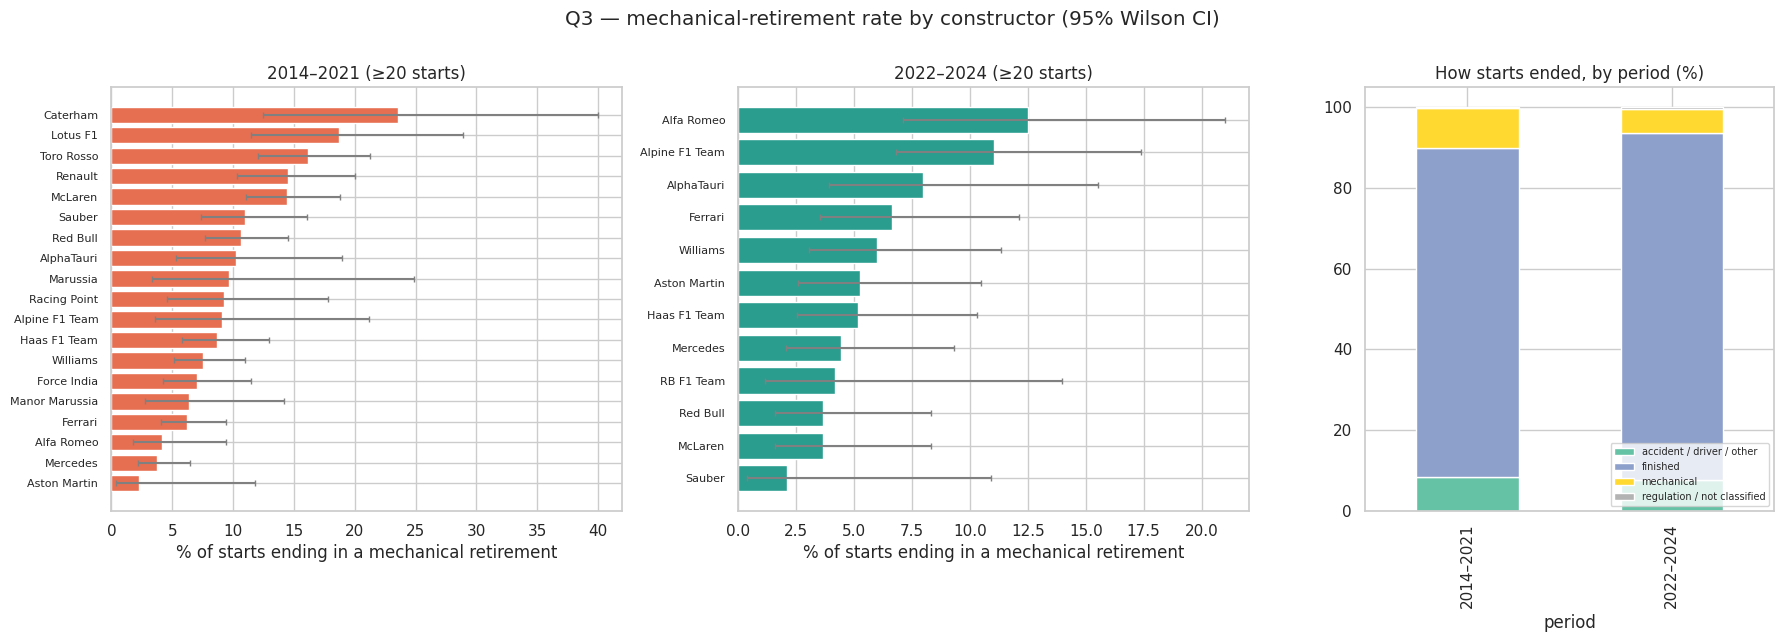

In [21]:
periods = sorted(q3t.period.unique())
fig, axes = plt.subplots(1, len(periods) + 1, figsize=(18, max(5, 0.32 * q3t.constructor.nunique())),
                         gridspec_kw={"width_ratios": [1] * len(periods) + [0.8]})
for ax, p in zip(axes, periods):
    g = q3t[q3t.period == p].sort_values("rate")
    ax.barh(g.constructor, g.rate * 100, xerr=[(g.rate - g.ci_low) * 100, (g.ci_high - g.rate) * 100],
            color="#e76f51" if p.startswith("2014") else "#2a9d8f", ecolor="grey", capsize=2)
    ax.set_title(f"{p} (≥{MIN_STARTS} starts)")
    ax.set_xlabel("% of starts ending in a mechanical retirement")
    ax.tick_params(axis="y", labelsize=8)
mix = pd.crosstab(q3.period, q3.status_group, normalize="index") * 100
mix.plot(kind="bar", stacked=True, ax=axes[-1], colormap="Set2")
axes[-1].set_title("How starts ended, by period (%)")
axes[-1].legend(fontsize=7, loc="lower right")
fig.suptitle("Q3 — mechanical-retirement rate by constructor (95% Wilson CI)", y=1.0)
fig.tight_layout()
savefig(fig, "q3_mechanical_retirements", "Q3: mechanical-retirement rate per constructor, hybrid era vs "
        "ground-effect era, and the overall mix of race outcomes.")

**Answer — Q3.** The overall mechanical-retirement rate fell from **9.7% of starts in 2014–2021** to
**6.1% in 2022–2024**. Highest rates:

| period | 1st | 2nd | 3rd |
|---|---|---|---|
| 2014–2021 | Caterham 23.5% (34 starts) | Lotus F1 18.7% (75) | Toro Rosso 16.1% (242) |
| 2022–2024 | Alfa Romeo 12.5% (88) | Alpine F1 Team 11.0% (136) | AlphaTauri 8.0% (88) |

The Wilson 95% intervals are wide for teams with few starts (Caterham has only 34), so the exact order is
uncertain; the drop between the two periods is the more solid finding.

* **Grain:** one row per driver per race start; results → status → races (year) → constructors. Constructor
  identity follows `constructorId`, so renamed teams (Toro Rosso → AlphaTauri → RB) are counted separately.
* **Missingness:** every start has a status. The status → category mapping is ours and is saved in
  `tables/q3_status_mapping.csv`. **Limitation:** the generic status "Retired" (50 starts) is counted as
  non-mechanical, and "Wheel", "Front wing", "Rear wing" and "Undertray" are counted as mechanical although some
  of them may come from contact or pit stops, so the rates are approximate.
* **Pre-race cutoff:** not relevant for this descriptive question; status is post-race information and is never
  used as a feature for the current race (only shifted to past races in `mech_dnf_last10`).

*Numbers from the full Kaggle run (Version 1, 17 Oct 2026). Re-check them if the code or data change.*

## 5. Feature engineering (leakage-safe) and feature selection

### 5.1 What is allowed at the cutoff
Prediction is made after qualifying and before the start. The audit below classifies every candidate column.

In [22]:
leakage_audit = pd.DataFrame([
    ("results.grid", "allowed", "starting position, fixed before the start (after penalties)"),
    ("qualifying.position / q1–q3", "allowed", "qualifying is finished before the cutoff"),
    ("driver/constructor standings of the PREVIOUS race", "allowed", "known before this race"),
    ("past results (rolling form, shifted by one race)", "allowed", "only races strictly before this one"),
    ("races.year / round / circuit, drivers.nationality, field size", "allowed", "calendar and entry list"),
    ("results.position / positionText / positionOrder", "forbidden", "the outcome itself (target source)"),
    ("results.points / laps / time / milliseconds", "forbidden", "post-race"),
    ("results.fastestLap / rank / fastestLapTime / Speed", "forbidden", "post-race"),
    ("results.statusId / status", "forbidden", "post-race (why the race ended)"),
    ("standings of THIS race", "forbidden", "include this race's points"),
    ("lap_times, pit_stops", "forbidden", "recorded during the race"),
    ("sprint_results (2021+)", "allowed but not used", "pre-race, but only ~6 races/season, format changed yearly"),
], columns=["column(s)", "verdict", "reason"])
savetable(leakage_audit, "leakage_audit")
leakage_audit

,column(s),verdict,reason
0,results.grid,allowed,"starting position, fixed before the start (aft..."
1,qualifying.position / q1–q3,allowed,qualifying is finished before the cutoff
2,driver/constructor standings of the PREVIOUS race,allowed,known before this race
3,"past results (rolling form, shifted by one race)",allowed,only races strictly before this one
4,"races.year / round / circuit, drivers.national...",allowed,calendar and entry list
5,results.position / positionText / positionOrder,forbidden,the outcome itself (target source)
6,results.points / laps / time / milliseconds,forbidden,post-race
7,results.fastestLap / rank / fastestLapTime / S...,forbidden,post-race
8,results.statusId / status,forbidden,post-race (why the race ended)
9,standings of THIS race,forbidden,include this race's points


### 5.2 Building the features
All "form" features use `shift(1)` on the driver/constructor time line ordered by race date, so the current race
is never included. Standings are taken from the **previous round of the same season** (round 1 → 0 points).

In [23]:
df = base.copy().sort_values(["date", "raceId", "driverId"]).reset_index(drop=True)
df["field_size"] = df.groupby("raceId").driverId.transform("size")
df["status_group"] = df.status.map(status_group)
df["mech_dnf"] = (df.status_group == "mechanical").astype(int)
df["finish_pct"] = (df.positionOrder - 1) / (df.field_size - 1).clip(lower=1)   # 0 = winner, 1 = last (post-race,
#                                                                                    only used shifted)
# --- grid group
df["pit_lane_start"] = (df.grid.fillna(0) == 0).astype(int)
df["grid_pos"] = df.grid.where(df.grid > 0, df.field_size).astype(float)   # pit lane -> back of the field
df["grid_pct"] = (df.grid_pos - 1) / (df.field_size - 1).clip(lower=1)
df["front_row"] = (df.grid_pos <= 2).astype(int)

# --- qualifying group
ql = clean["qualifying"].drop_duplicates(["raceId", "driverId"]).copy()
ql["best_q"] = ql[["q1", "q2", "q3"]].min(axis=1)
ql["pole_q"] = ql.groupby("raceId").best_q.transform("min")
ql["quali_gap_pct"] = 100 * (ql.best_q - ql.pole_q) / ql.pole_q
df = df.merge(ql[["raceId", "driverId", "position", "quali_gap_pct"]].rename(columns={"position": "quali_pos"}),
              on=["raceId", "driverId"], how="left")
df["quali_pos"] = df.quali_pos.astype(float)
df["grid_minus_quali"] = df.grid_pos - df.quali_pos      # > 0 : penalty / moved back

# --- standings before the race (previous round, same season)
races_c = clean["races"][["raceId", "year", "round"]].sort_values(["year", "round"])
races_c["prev_raceId"] = races_c.groupby("year").raceId.shift(1)
df = df.merge(races_c[["raceId", "prev_raceId"]], on="raceId", how="left")


def prev_standings(stand, key, prefix):
    s = stand[["raceId", key, "points", "position", "wins"]].rename(
        columns={"raceId": "prev_raceId", "points": f"{prefix}_pts_before", "position": f"{prefix}_rank_before",
                 "wins": f"{prefix}_wins_before"})
    s["prev_raceId"] = s.prev_raceId.astype(float)
    s[f"{prefix}_leader_pts"] = s.groupby("prev_raceId")[f"{prefix}_pts_before"].transform("max")
    return s


df["prev_raceId"] = df.prev_raceId.astype(float)
df = df.merge(prev_standings(clean["driver_standings"], "driverId", "drv"), on=["prev_raceId", "driverId"],
              how="left")
cons_prev = prev_standings(clean["constructor_standings"], "constructorId", "con")
df = df.merge(cons_prev, on=["prev_raceId", "constructorId"], how="left")
for p in ["drv", "con"]:
    first_round = df.prev_raceId.isna()
    has_table = df.year >= (1958 if p == "con" else 1950)
    for c in [f"{p}_pts_before", f"{p}_wins_before"]:
        df[c] = df[c].astype(float)
        df.loc[has_table & df[c].isna(), c] = 0.0          # first round / not yet classified: 0 points
    df[f"{p}_rank_before"] = df[f"{p}_rank_before"].astype(float)
    df.loc[has_table & df[f"{p}_rank_before"].isna(), f"{p}_rank_before"] = df.field_size  # unranked -> last
    df[f"{p}_pts_share"] = np.where(df[f"{p}_leader_pts"].fillna(0) > 0,
                                    df[f"{p}_pts_before"] / df[f"{p}_leader_pts"], 0.0)
    df.loc[~has_table, f"{p}_pts_share"] = np.nan
df["first_round"] = df.prev_raceId.isna().astype(int)


# --- driver form (past races only)
def past_mean(frame, by, col, window=None):
    g = frame.groupby(by, sort=False)[col]
    if window is None:
        return g.transform(lambda s: s.shift(1).expanding().mean())
    return g.transform(lambda s: s.shift(1).rolling(window, min_periods=1).mean())


df["drv_podium_rate_last5"] = past_mean(df, "driverId", "podium", 5)
df["drv_finish_pct_last5"] = past_mean(df, "driverId", "finish_pct", 5)
df["drv_grid_pct_last5"] = past_mean(df, "driverId", "grid_pct", 5)
df["drv_mech_dnf_last10"] = past_mean(df, "driverId", "mech_dnf", 10)
df["drv_career_podium_rate"] = past_mean(df, "driverId", "podium")
df["drv_starts_before"] = df.groupby("driverId").cumcount()
df["drv_circuit_podium_rate"] = past_mean(df, ["driverId", "circuitId"], "podium")

# --- constructor form: aggregate per team and race first, then shift on the team's own time line
team_race = (df.groupby(["constructorId", "raceId", "date"], as_index=False)
             .agg(t_podium=("podium", "mean"), t_finish=("finish_pct", "mean"), t_mech=("mech_dnf", "mean"))
             .sort_values(["date", "raceId"]))
team_race["con_podium_rate_last5"] = past_mean(team_race, "constructorId", "t_podium", 5)
team_race["con_finish_pct_last5"] = past_mean(team_race, "constructorId", "t_finish", 5)
team_race["con_mech_dnf_last10"] = past_mean(team_race, "constructorId", "t_mech", 10)
df = df.merge(team_race[["constructorId", "raceId", "con_podium_rate_last5", "con_finish_pct_last5",
                         "con_mech_dnf_last10"]], on=["constructorId", "raceId"], how="left")

# --- context
df = df.merge(dq[["raceId", "driverId", "home"]], on=["raceId", "driverId"], how="left")
df["home_race"] = df.home.fillna(False).astype(int)

FEATURE_GROUPS = {
    "grid": ["grid_pos", "grid_pct", "front_row", "pit_lane_start"],
    "qualifying": ["quali_pos", "quali_gap_pct", "grid_minus_quali"],
    "standings": ["drv_pts_share", "drv_rank_before", "drv_wins_before", "con_pts_share", "con_rank_before",
                  "con_wins_before", "first_round"],
    "driver_form": ["drv_podium_rate_last5", "drv_finish_pct_last5", "drv_grid_pct_last5", "drv_mech_dnf_last10",
                    "drv_career_podium_rate", "drv_starts_before", "drv_circuit_podium_rate"],
    "constructor_form": ["con_podium_rate_last5", "con_finish_pct_last5", "con_mech_dnf_last10"],
    "context": ["field_size", "home_race"],
}
ALL_FEATURES = [f for g in FEATURE_GROUPS.values() for f in g]
df = df.sort_values(["date", "raceId", "driverId"]).reset_index(drop=True)
assert not df.duplicated(["raceId", "driverId"]).any(), "grain broken"
print(f"Modelling table: {len(df):,} rows × {len(ALL_FEATURES)} candidate features; podium rate {df.podium.mean():.1%}")
df[["year", "raceId", "driverId", "podium"] + ALL_FEATURES].sample(5, random_state=SEED)

Modelling table: 24,677 rows × 26 candidate features; podium rate 13.5%


,year,raceId,driverId,podium,grid_pos,grid_pct,front_row,pit_lane_start,quali_pos,quali_gap_pct,grid_minus_quali,drv_pts_share,drv_rank_before,drv_wins_before,con_pts_share,con_rank_before,con_wins_before,first_round,drv_podium_rate_last5,drv_finish_pct_last5,drv_grid_pct_last5,drv_mech_dnf_last10,drv_career_podium_rate,drv_starts_before,drv_circuit_podium_rate,con_podium_rate_last5,con_finish_pct_last5,con_mech_dnf_last10,field_size,home_race
21705,2018,989,1,1,1.0,0.0,1,0,1.0,0.000000,0.0,0.000000,20.0,0.0,0.000000,20.0,0.0,1,0.6,0.126316,0.231579,0.0,0.562500,208,0.636364,0.6,0.110526,0.000000,20,0
2789,1967,679,374,0,13.0,0.705882,0,0,NaN,NaN,NaN,0.000000,18.0,0.0,0.000000,18.0,0.0,1,0.0,0.448830,0.614108,0.6,0.041667,24,NaN,0.1,0.525527,0.533333,18,0
18114,2009,10,17,1,3.0,0.111111,0,0,3.0,0.000000,0.0,0.669118,3.0,1.0,0.825893,2.0,3.0,0,0.8,0.084211,0.168421,0.0,0.053435,131,0.000000,0.7,0.163158,0.000000,19,0
22937,2021,1054,846,0,7.0,0.315789,0,0,7.0,0.657962,0.0,0.613636,3.0,0.0,0.683333,3.0,0.0,0,0.2,0.221053,0.431579,0.1,0.051282,39,0.000000,0.1,0.231579,0.050000,20,0
2361,1964,715,385,1,7.0,0.315789,0,0,NaN,NaN,NaN,0.187500,9.0,0.0,0.558824,3.0,1.0,0,0.2,0.484823,0.379708,0.5,0.100000,20,NaN,0.4,0.439002,0.550000,20,0


### 5.3 Leakage tests
1. **Brute-force check** of the rolling form: recompute `drv_podium_rate_last5` for random rows from scratch using
   only that driver's strictly earlier races, and compare.
2. **What leakage would look like**: a model given the standings *after* the race gets an unrealistically high
   score — a reminder of why the shift matters.

In [24]:
rng = np.random.default_rng(SEED)
check_idx = rng.choice(df.index, size=min(300, len(df)), replace=False)
mismatch = 0
for i in check_idx:
    row = df.loc[i]
    past = df[(df.driverId == row.driverId) & (df.date < row.date)].sort_values("date").tail(5)
    expected = past.podium.mean() if len(past) else np.nan
    got = row.drv_podium_rate_last5
    if not ((np.isnan(expected) and np.isnan(got)) or np.isclose(expected, got)):
        mismatch += 1
print(f"Rolling-form brute-force check: {mismatch} mismatches in {len(check_idx)} random rows")
assert mismatch == 0

post = clean["driver_standings"][["raceId", "driverId", "points"]].rename(columns={"points": "pts_after"})
leak_demo = df.merge(post, on=["raceId", "driverId"], how="left")
leak_demo["pts_gain_this_race"] = leak_demo.pts_after.astype(float) - leak_demo.drv_pts_before
tr_m, va_m = leak_demo.year <= TRAIN_END, leak_demo.year.between(TRAIN_END + 1, VAL_END)
leak_rows = []
for name, feats in [("safe: grid + standings before", ["grid_pos", "drv_pts_share", "con_pts_share"]),
                    ("LEAKY: + points gained this race", ["grid_pos", "drv_pts_share", "con_pts_share",
                                                          "pts_gain_this_race"])]:
    X = leak_demo[feats].fillna(0)
    m = Pipeline([("s", StandardScaler()), ("lr", LogisticRegression(max_iter=1000))]).fit(X[tr_m],
                                                                                            leak_demo.podium[tr_m])
    pv = m.predict_proba(X[va_m])[:, 1]
    leak_rows.append({"feature set": name, "val ROC-AUC": roc_auc_score(leak_demo.podium[va_m], pv),
                      "val PR-AUC": average_precision_score(leak_demo.podium[va_m], pv)})
leak_table = savetable(pd.DataFrame(leak_rows), "leakage_demo")
leak_table.round(3)

Rolling-form brute-force check: 0 mismatches in 300 random rows


,feature set,val ROC-AUC,val PR-AUC
0,safe: grid + standings before,0.921,0.708
1,LEAKY: + points gained this race,0.998,0.989


### 5.4 Evidence for each feature (training seasons only)
Univariate evidence is computed on the training split only so that the selection itself does not peek at
validation/test data: single-feature ROC-AUC (orientation-free: max(AUC, 1−AUC)), Spearman correlation with the
target, missing share, and the binned podium rate.

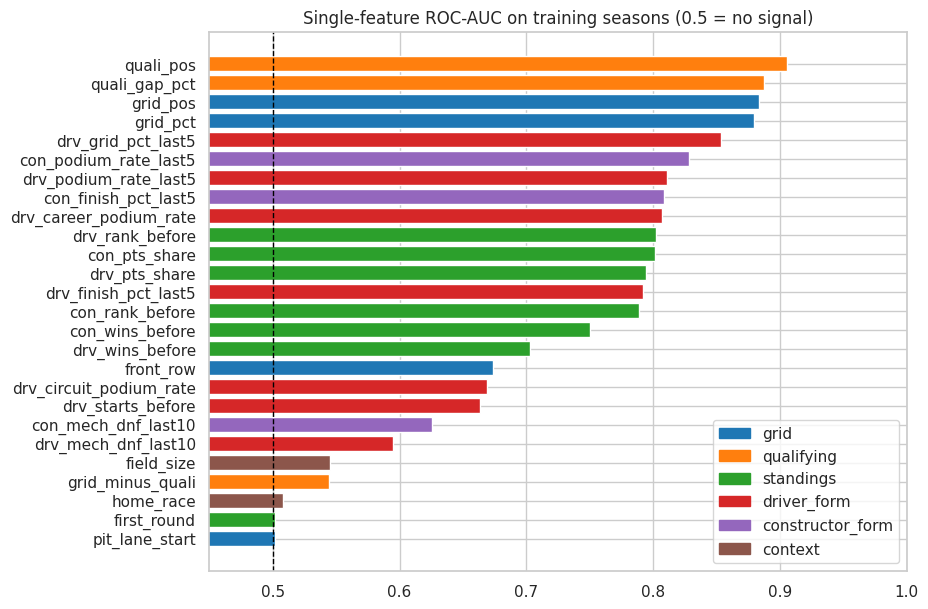

,group,feature,single-feature AUC,direction,Spearman ρ,missing % (train)
4,qualifying,quali_pos,0.906,lower → podium,-0.487,63.086
5,qualifying,quali_gap_pct,0.887,lower → podium,-0.466,63.680
0,grid,grid_pos,0.883,lower → podium,-0.453,0.000
1,grid,grid_pct,0.879,lower → podium,-0.447,0.000
16,driver_form,drv_grid_pct_last5,0.853,lower → podium,-0.421,2.981
21,constructor_form,con_podium_rate_last5,0.829,higher → podium,0.422,1.144
14,driver_form,drv_podium_rate_last5,0.811,higher → podium,0.442,2.981
22,constructor_form,con_finish_pct_last5,0.808,lower → podium,-0.365,1.144
18,driver_form,drv_career_podium_rate,0.807,higher → podium,0.375,2.981
8,standings,drv_rank_before,0.802,lower → podium,-0.357,0.000


In [25]:
train_mask_all = df.year <= TRAIN_END
tr = df[train_mask_all]
ev = []
for g, feats in FEATURE_GROUPS.items():
    for f in feats:
        x = tr[f]
        ok = x.notna()
        auc = roc_auc_score(tr.podium[ok], x[ok]) if ok.sum() > 50 and x[ok].nunique() > 1 else np.nan
        rho_f = stats.spearmanr(x[ok], tr.podium[ok]).statistic if ok.sum() > 50 else np.nan
        ev.append({"group": g, "feature": f, "single-feature AUC": max(auc, 1 - auc) if auc == auc else np.nan,
                   "direction": "higher → podium" if auc > 0.5 else "lower → podium",
                   "Spearman ρ": rho_f, "missing % (train)": 100 * (1 - ok.mean())})
evidence = savetable(pd.DataFrame(ev).sort_values("single-feature AUC", ascending=False), "feature_evidence")

fig, ax = plt.subplots(figsize=(9, 7))
pal = dict(zip(FEATURE_GROUPS, sns.color_palette("tab10", len(FEATURE_GROUPS))))
ax.barh(evidence.feature, evidence["single-feature AUC"], color=evidence.group.map(pal))
ax.axvline(0.5, color="black", lw=1, ls="--")
ax.set_xlim(0.45, 1)
ax.invert_yaxis()
ax.set_title("Single-feature ROC-AUC on training seasons (0.5 = no signal)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in pal.values()], labels=list(pal), loc="lower right")
savefig(fig, "features_univariate_auc", "Univariate predictive power of each candidate feature (training data).")
evidence.round(3)

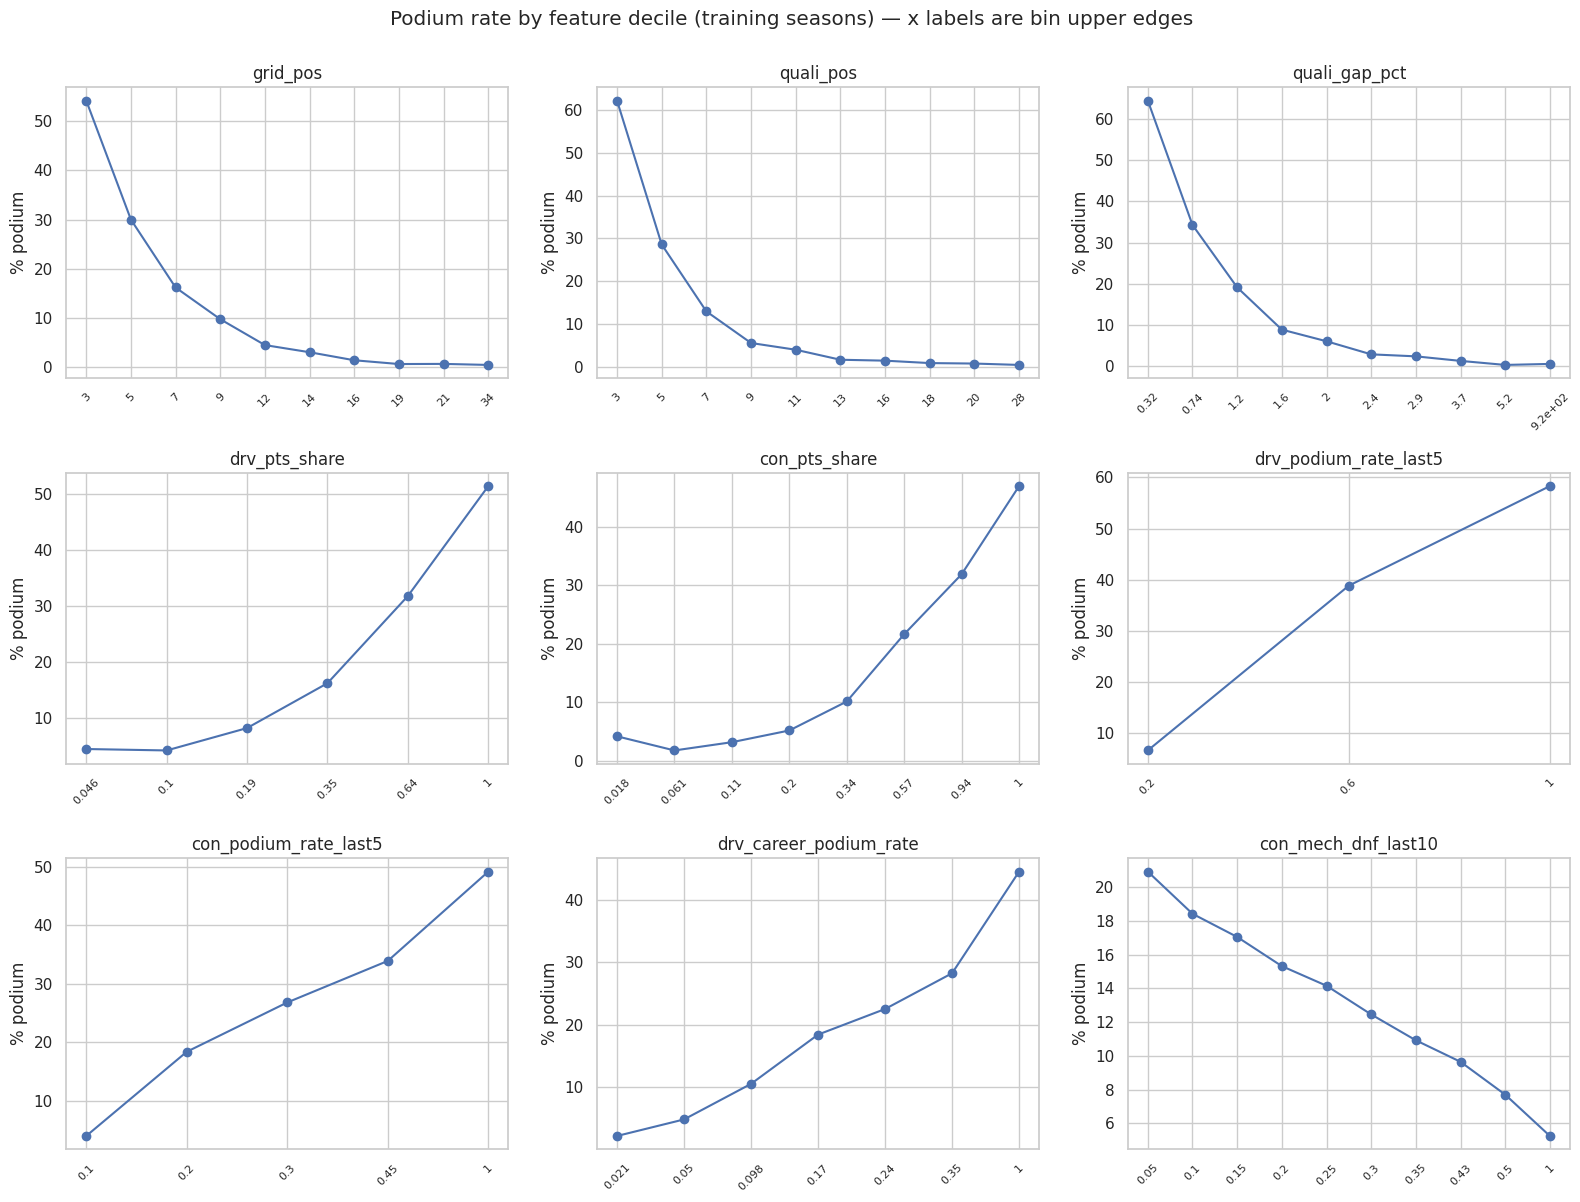

In [26]:
show = ["grid_pos", "quali_pos", "quali_gap_pct", "drv_pts_share", "con_pts_share", "drv_podium_rate_last5",
        "con_podium_rate_last5", "drv_career_podium_rate", "con_mech_dnf_last10"]
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for ax, f in zip(axes.flat, show):
    x = tr[[f, "podium"]].dropna()
    try:
        bins = pd.qcut(x[f], 10, duplicates="drop")
    except ValueError:
        bins = pd.cut(x[f], 10)
    rate = x.groupby(bins, observed=True).podium.mean() * 100
    ax.plot(range(len(rate)), rate.values, marker="o")
    ax.set_xticks(range(len(rate)))
    ax.set_xticklabels([f"{iv.right:.2g}" for iv in rate.index], rotation=45, fontsize=8)
    ax.set_title(f)
    ax.set_ylabel("% podium")
fig.suptitle("Podium rate by feature decile (training seasons) — x labels are bin upper edges", y=1.0)
fig.tight_layout()
savefig(fig, "features_binned_rates", "Podium rate across deciles of key features: monotone relationships support "
        "using them.")

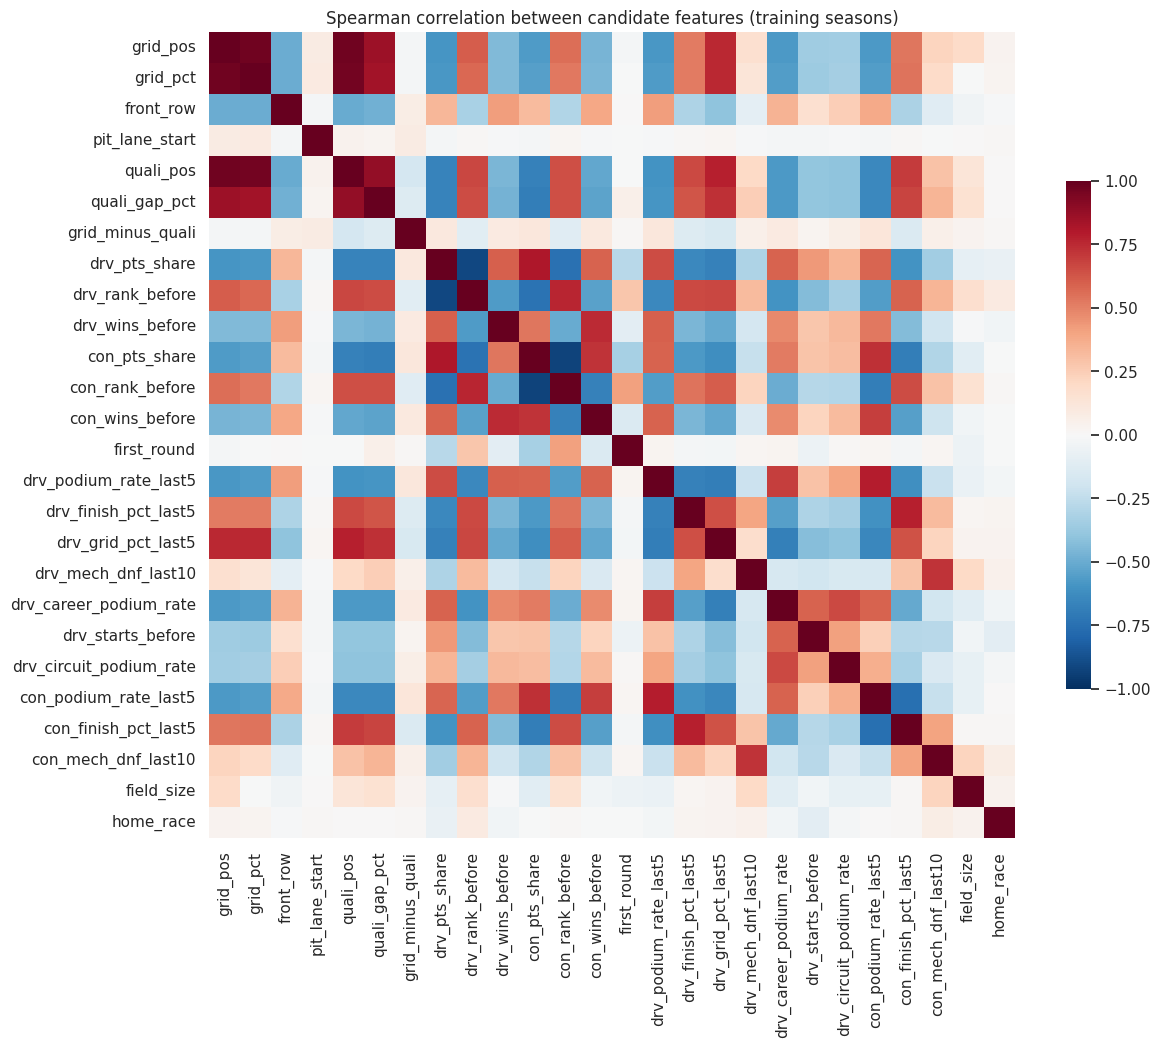

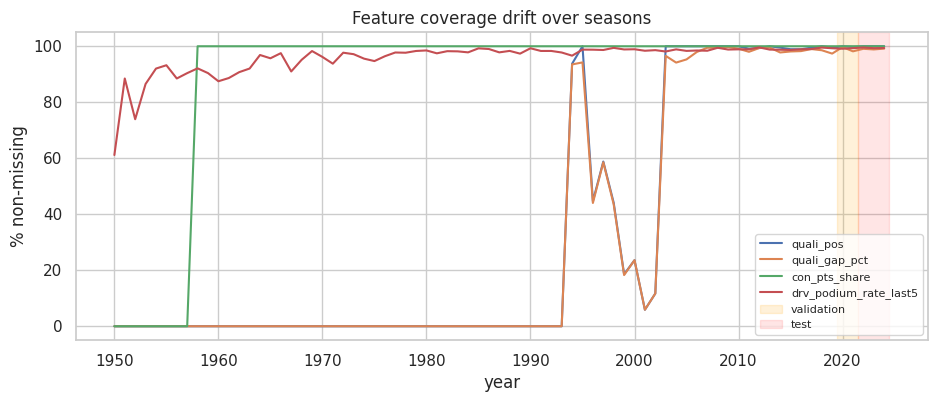

In [27]:
corr = tr[ALL_FEATURES].corr(method="spearman")
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, square=True, cbar_kws={"shrink": 0.6})
ax.set_title("Spearman correlation between candidate features (training seasons)")
savefig(fig, "features_correlation", "Feature redundancy check.")

cov = df.groupby("year")[["quali_pos", "quali_gap_pct", "con_pts_share", "drv_podium_rate_last5"]] \
    .apply(lambda g: g.notna().mean() * 100)
fig, ax = plt.subplots(figsize=(11, 4))
cov.plot(ax=ax)
ax.axvspan(TRAIN_END + 0.5, VAL_END + 0.5, color="orange", alpha=0.15, label="validation")
ax.axvspan(VAL_END + 0.5, df.year.max() + 0.5, color="red", alpha=0.1, label="test")
ax.set_ylabel("% non-missing")
ax.set_title("Feature coverage drift over seasons")
ax.legend(fontsize=8)
savefig(fig, "features_coverage_drift", "Qualifying features exist only from the mid-1990s; constructor standings "
        "from 1958.")

### 5.5 Selection rule (decided from the evidence above, training data only)
* Drop a feature if its single-feature AUC < 0.52 **and** it is not needed as an indicator for another feature.
* For a pair **inside the same group** with |Spearman ρ| > 0.95, keep the one with fewer missing values (then the
  higher AUC). Pairs across groups (e.g. grid vs qualifying position) are kept on purpose: they come from different
  sources, differ exactly when penalties apply, and qualifying is missing before the mid-1990s while grid is not.

In [28]:
KEEP_INDICATORS = {"pit_lane_start", "first_round"}
auc_of = evidence.set_index("feature")["single-feature AUC"]
dropped = {}
for f in ALL_FEATURES:
    if f not in KEEP_INDICATORS and (np.isnan(auc_of[f]) or auc_of[f] < 0.52):
        dropped[f] = f"weak univariate signal (AUC {auc_of[f]:.3f})"
miss_of = evidence.set_index("feature")["missing % (train)"]
for g, feats in FEATURE_GROUPS.items():
    cands = [f for f in feats if f not in dropped]
    for i, a in enumerate(cands):
        for b in cands[i + 1:]:
            if a in dropped or b in dropped or abs(corr.loc[a, b]) <= 0.95:
                continue
            loser = max([a, b], key=lambda f: (miss_of[f], -auc_of[f]))
            dropped[loser] = f"redundant with {b if loser == a else a} (|ρ|={abs(corr.loc[a, b]):.2f})"
FEATURES = [f for f in ALL_FEATURES if f not in dropped]
GROUPS = {g: [f for f in fs if f in FEATURES] for g, fs in FEATURE_GROUPS.items()}
GROUPS = {g: fs for g, fs in GROUPS.items() if fs}
REPORT["dropped_features"] = dropped
print(f"Selected {len(FEATURES)} features. Dropped:")
for f, why in dropped.items():
    print(f"  - {f}: {why}")

Selected 24 features. Dropped:
  - home_race: weak univariate signal (AUC 0.508)
  - grid_pct: redundant with grid_pos (|ρ|=0.97)


## 6. Train / validation / test split

**Temporal split by season**: train ≤ 2019, validation 2020–2021, test 2022–2024.
* The task is forecasting future races, so evaluation must be on seasons the model has not seen.
* A random split would put races from the same season (same cars, same standings) on both sides and leak era
  information; rolling form features also cross season boundaries.
* 2022 starts a new technical era, so the test set also measures robustness to a regulation change.

**Training window.** Whether to use all seasons from 1950 or only modern ones (qualifying coverage drift) is
decided empirically on the validation set in section 8.1.

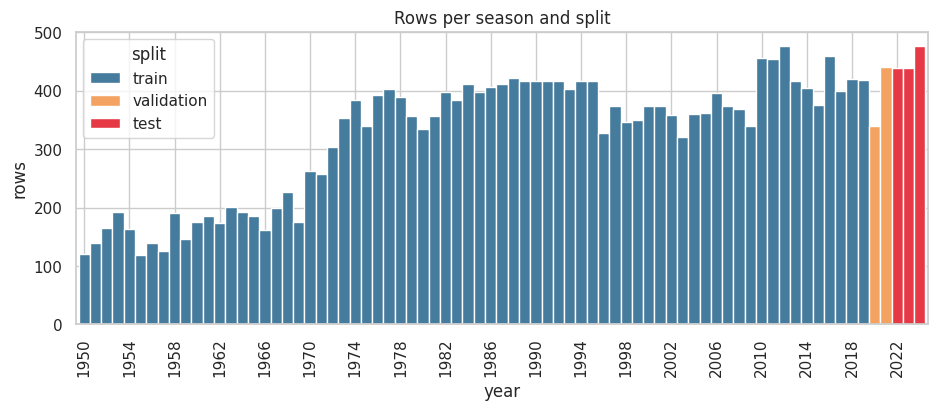

,seasons,rows,races,podium_rate
split,,,,
train,1950–2019,22544,1007,0.134005
validation,2020–2021,779,39,0.150193
test,2022–2024,1354,68,0.150665


In [29]:
split = np.select([df.year <= TRAIN_END, df.year <= VAL_END], ["train", "validation"], "test")
df["split"] = split
split_summary = df.groupby("split").agg(seasons=("year", lambda s: f"{s.min()}–{s.max()}"), rows=("podium", "size"),
                                        races=("raceId", "nunique"), podium_rate=("podium", "mean")) \
    .loc[["train", "validation", "test"]]
savetable(split_summary, "split_summary")
fig, ax = plt.subplots(figsize=(11, 3.8))
yearly = df.groupby(["year", "split"]).size().unstack(fill_value=0)[["train", "validation", "test"]]
yearly.plot(kind="bar", stacked=True, ax=ax, width=1, color=["#457b9d", "#f4a261", "#e63946"])
ax.xaxis.set_major_locator(plt.MaxNLocator(20))
ax.set_ylabel("rows")
ax.set_title("Rows per season and split")
savefig(fig, "split", "Temporal split.")
split_summary

## 7. Pre-processing

* **Imputation**: median, fitted on the training rows only, plus a missing-indicator column for every feature
  that has missing values (e.g. qualifying before 1994 — the indicator lets the model learn that "no qualifying
  data" is different from an average qualifying result).
* **Scaling**: standardisation for the linear model and the neural network (gradient-based, scale-sensitive).
  Tree models get imputation only (or native NaN handling for gradient boosting).

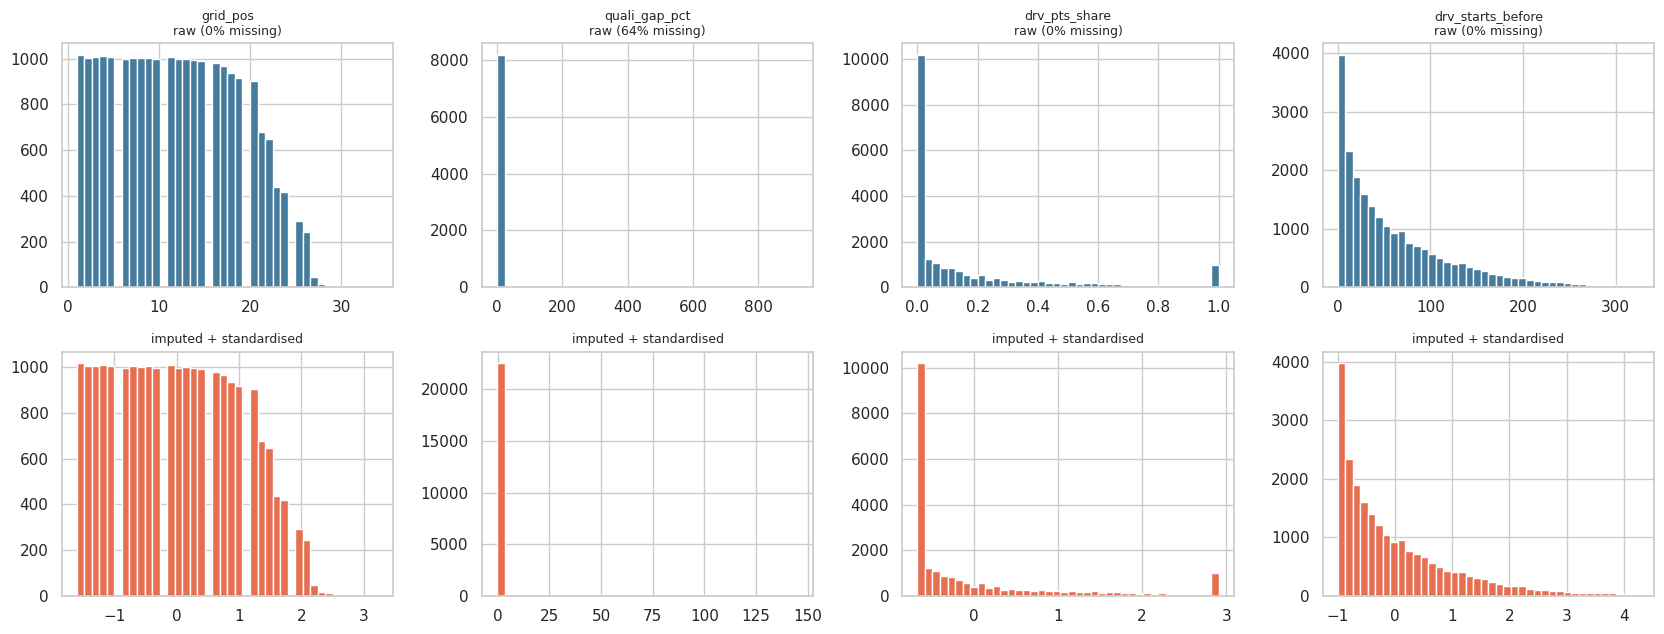

,missing before,mean before,std before,min before,max before,missing after,mean after,std after,min after,max after
grid_pos,0,11.94,6.84,1.00,34.00,0,-0.0,1.0,-1.60,3.23
front_row,0,0.09,0.29,0.00,1.00,0,-0.0,1.0,-0.31,3.19
pit_lane_start,0,0.00,0.06,0.00,1.00,0,-0.0,1.0,-0.06,17.54
quali_pos,14222,11.37,6.37,1.00,28.00,0,0.0,1.0,-2.62,4.36
quali_gap_pct,14356,2.62,10.49,0.00,922.86,0,-0.0,1.0,-0.35,145.43
grid_minus_quali,14222,0.00,1.42,-9.00,23.00,0,0.0,1.0,-10.40,26.59
drv_pts_share,0,0.19,0.28,0.00,1.00,0,-0.0,1.0,-0.67,2.91
drv_rank_before,0,14.24,9.21,1.00,102.00,0,0.0,1.0,-1.44,9.53
drv_wins_before,0,0.32,1.03,0.00,13.00,0,0.0,1.0,-0.31,12.27
con_pts_share,1163,0.27,0.33,0.00,1.00,0,-0.0,1.0,-0.81,2.26


In [30]:
def make_pre(scale=True):
    steps = [("impute", SimpleImputer(strategy="median", add_indicator=True))]
    if scale:
        steps.append(("scale", StandardScaler()))
    return steps


def xy(frame, feats=None):
    feats = feats or FEATURES
    return frame[feats].astype(float), frame.podium.astype(int).to_numpy()


pre = Pipeline(make_pre()).fit(df.loc[df.split == "train", FEATURES].astype(float))
X_tr_raw = df.loc[df.split == "train", FEATURES].astype(float)
X_tr_pre = pd.DataFrame(pre.transform(X_tr_raw)[:, :len(FEATURES)], columns=FEATURES)
effect = pd.DataFrame({"missing before": X_tr_raw.isna().sum(), "mean before": X_tr_raw.mean(),
                       "std before": X_tr_raw.std(), "min before": X_tr_raw.min(), "max before": X_tr_raw.max(),
                       "missing after": X_tr_pre.isna().sum(), "mean after": X_tr_pre.mean(),
                       "std after": X_tr_pre.std(), "min after": X_tr_pre.min(), "max after": X_tr_pre.max()})
savetable(effect, "preprocessing_effect")
demo_feats = [f for f in ["grid_pos", "quali_gap_pct", "drv_pts_share", "drv_starts_before"] if f in FEATURES]
fig, axes = plt.subplots(2, len(demo_feats), figsize=(4.2 * len(demo_feats), 6.5))
for j, f in enumerate(demo_feats):
    axes[0, j].hist(X_tr_raw[f].dropna(), bins=40, color="#457b9d")
    axes[0, j].set_title(f"{f}\nraw ({X_tr_raw[f].isna().mean():.0%} missing)", fontsize=9)
    axes[1, j].hist(X_tr_pre[f], bins=40, color="#e76f51")
    axes[1, j].set_title("imputed + standardised", fontsize=9)
fig.tight_layout()
savefig(fig, "preprocessing_effect", "Effect of imputation and scaling on feature distributions: scaling changes "
        "the range, not the shape; median imputation creates a spike that the missing indicator lets the model "
        "separate.")
effect.round(2)

### 7.1 Pre-processing-order experiments
All three use the logistic-regression baseline so that only the pre-processing differs.
* **E1 — where the imputer/scaler is fitted**: on training rows only (correct) vs on all rows *before* splitting.
* **E2 — oversampling before vs after the split** (random split): duplicating podium rows before splitting copies
  the same rows into the validation set.
* **E3 — impute → scale vs scale → impute**.

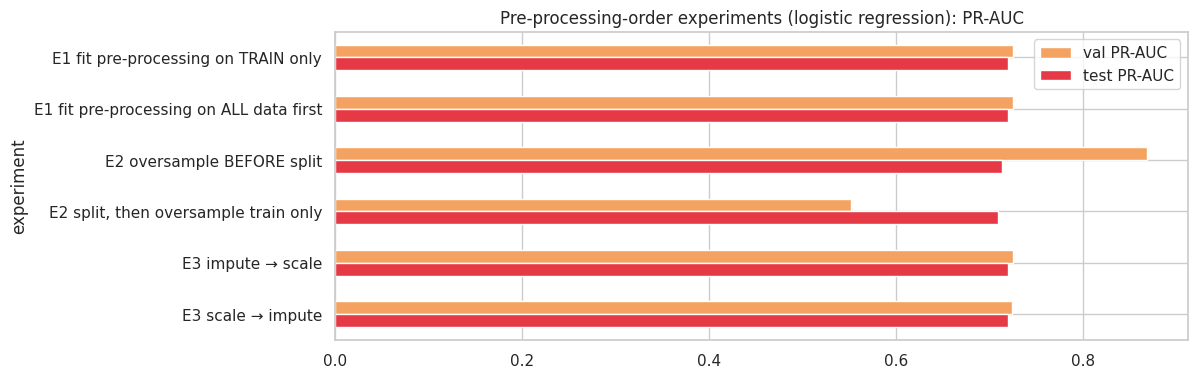

,val ROC-AUC,val PR-AUC,val F1,val Precision,val Recall,test ROC-AUC,test PR-AUC,test F1,test Precision,test Recall
experiment,,,,,,,,,,
E1 fit pre-processing on TRAIN only,0.933,0.725,0.703,0.605,0.838,0.938,0.720,0.667,0.530,0.897
E1 fit pre-processing on ALL data first,0.933,0.725,0.701,0.623,0.803,0.938,0.720,0.678,0.547,0.892
E2 oversample BEFORE split,0.899,0.869,0.831,0.780,0.889,0.938,0.713,0.598,0.438,0.946
"E2 split, then oversample train only",0.900,0.553,0.578,0.477,0.733,0.936,0.710,0.673,0.569,0.824
E3 impute → scale,0.933,0.725,0.703,0.605,0.838,0.938,0.720,0.667,0.530,0.897
E3 scale → impute,0.933,0.724,0.701,0.617,0.812,0.938,0.721,0.674,0.542,0.892


In [31]:
def metrics(y, p, thr):
    yhat = (p >= thr).astype(int)
    return {"ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p), "F1": f1_score(y, yhat),
            "Precision": precision_score(y, yhat, zero_division=0), "Recall": recall_score(y, yhat)}


def best_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    i = int(np.nanargmax(f1[:-1]))
    return float(thr[i])


trn, val, tst = (df[df.split == s] for s in ["train", "validation", "test"])
Xtr, ytr = xy(trn)
Xva, yva = xy(val)
Xte, yte = xy(tst)
base_lr = LogisticRegression(max_iter=3000, C=1.0)
exp_rows = []

# E1
correct = Pipeline(make_pre() + [("m", clone(base_lr))]).fit(Xtr, ytr)
full_pre = Pipeline(make_pre()).fit(pd.concat([Xtr, Xva, Xte]))
leaky_m = clone(base_lr).fit(full_pre.transform(Xtr), ytr)
for name, pv, pt in [("E1 fit pre-processing on TRAIN only", correct.predict_proba(Xva)[:, 1],
                      correct.predict_proba(Xte)[:, 1]),
                     ("E1 fit pre-processing on ALL data first", leaky_m.predict_proba(full_pre.transform(Xva))[:, 1],
                      leaky_m.predict_proba(full_pre.transform(Xte))[:, 1])]:
    thr = best_threshold(yva, pv)
    exp_rows.append({"experiment": name, **{f"val {k}": v for k, v in metrics(yva, pv, thr).items()},
                     **{f"test {k}": v for k, v in metrics(yte, pt, thr).items()}})

# E2 (random split inside the training seasons; test = the real test seasons)
pos_idx = np.where(ytr == 1)[0]
ratio = int((ytr == 0).sum() / max(len(pos_idx), 1)) - 1
over_before_X = pd.concat([Xtr] + [Xtr.iloc[pos_idx]] * ratio, ignore_index=True)
over_before_y = np.concatenate([ytr] + [ytr[pos_idx]] * ratio)
a_tr, a_va, ay_tr, ay_va = train_test_split(over_before_X, over_before_y, test_size=0.2, random_state=SEED,
                                            stratify=over_before_y)
b_tr, b_va, by_tr, by_va = train_test_split(Xtr, ytr, test_size=0.2, random_state=SEED, stratify=ytr)
bp = np.where(by_tr == 1)[0]
b_tr = pd.concat([b_tr] + [b_tr.iloc[bp]] * ratio, ignore_index=True)
by_tr = np.concatenate([by_tr] + [by_tr[bp]] * ratio)
for name, (X1, y1, X2, y2) in [("E2 oversample BEFORE split", (a_tr, ay_tr, a_va, ay_va)),
                               ("E2 split, then oversample train only", (b_tr, by_tr, b_va, by_va))]:
    m = Pipeline(make_pre() + [("m", clone(base_lr))]).fit(X1, y1)
    pv, pt = m.predict_proba(X2)[:, 1], m.predict_proba(Xte)[:, 1]
    thr = best_threshold(y2, pv)
    exp_rows.append({"experiment": name, **{f"val {k}": v for k, v in metrics(y2, pv, thr).items()},
                     **{f"test {k}": v for k, v in metrics(yte, pt, thr).items()}})

# E3
for name, steps in [("E3 impute → scale", [("impute", SimpleImputer(strategy="median", add_indicator=True)),
                                           ("scale", StandardScaler())]),
                    ("E3 scale → impute", [("scale", StandardScaler()),
                                           ("impute", SimpleImputer(strategy="median", add_indicator=True))])]:
    m = Pipeline(steps + [("m", clone(base_lr))]).fit(Xtr, ytr)
    pv, pt = m.predict_proba(Xva)[:, 1], m.predict_proba(Xte)[:, 1]
    thr = best_threshold(yva, pv)
    exp_rows.append({"experiment": name, **{f"val {k}": v for k, v in metrics(yva, pv, thr).items()},
                     **{f"test {k}": v for k, v in metrics(yte, pt, thr).items()}})
order_exp = savetable(pd.DataFrame(exp_rows).set_index("experiment"), "preprocessing_order_experiments")
fig, ax = plt.subplots(figsize=(11, 4))
order_exp[["val PR-AUC", "test PR-AUC"]].plot(kind="barh", ax=ax, color=["#f4a261", "#e63946"])
ax.invert_yaxis()
ax.set_title("Pre-processing-order experiments (logistic regression): PR-AUC")
savefig(fig, "preprocessing_order", "Pre-processing order: a gap between validation and test PR-AUC exposes "
        "an optimistic (leaky) validation estimate.")
order_exp.round(3)

**Result of the pre-processing-order experiments.** E1: fitting the imputer/scaler on all rows gives almost the
same scores here (val PR-AUC 0.725 both ways), but it is still wrong in principle, so we fit on training rows only.
E2 shows real leakage: oversampling *before* the split copies podium rows into the validation set and inflates
validation PR-AUC to **0.869**, while the honest version gives **0.553**; on the untouched test seasons both
are about 0.71, so the 0.869 is fake. E3: the order of imputation and scaling makes no real difference
(0.725 vs 0.724).

*Numbers from the full Kaggle run (Version 1, 17 Oct 2026). Re-check them if the code or data change.*

## 8. Predictive modelling

**Metrics.** ROC-AUC, PR-AUC, F1, precision, recall, plus *top-3 hit rate* (in each race, mark the three highest
probabilities as the predicted podium; share of real podium finishers caught).
* **Primary metric: PR-AUC** — podiums are ~13–15% of rows; PR-AUC focuses on how well true podium finishers are
  ranked above the rest and is not inflated by the many easy negatives (unlike ROC-AUC).
* **Secondary metric: F1** at a threshold chosen on the validation set — the operational question "who do we call
  a podium".

**Protocol.** Every model is fitted on the training seasons; hyperparameters and the decision threshold are chosen
on validation; the test seasons are scored once at the end.

### 8.1 Training window (data experiment)

In [32]:
def top3_hit_rate(frame, p):
    t = frame[["raceId", "podium"]].assign(p=p)
    t["rk"] = t.groupby("raceId").p.rank(ascending=False, method="first")
    return t.loc[t.rk <= 3, "podium"].sum() / t.podium.sum()


window_rows = []
for start in [1950, 1980, 1994]:
    w = trn[trn.year >= start]
    X1, y1 = xy(w)
    m = Pipeline(make_pre() + [("m", clone(base_lr))]).fit(X1, y1)
    pv = m.predict_proba(Xva)[:, 1]
    window_rows.append({"train from": start, "train rows": len(w), "val PR-AUC": average_precision_score(yva, pv),
                        "val ROC-AUC": roc_auc_score(yva, pv), "val top-3 hit": top3_hit_rate(val, pv)})
window_exp = savetable(pd.DataFrame(window_rows).set_index("train from"), "training_window_experiment")
TRAIN_FROM = int(window_exp["val PR-AUC"].idxmax())
REPORT["train_from"] = TRAIN_FROM
trn = trn[trn.year >= TRAIN_FROM]
Xtr, ytr = xy(trn)
print(f"Chosen training window: {TRAIN_FROM}–{TRAIN_END} ({len(trn):,} rows) — best validation PR-AUC")
window_exp.round(3)

Chosen training window: 1980–2019 (15,728 rows) — best validation PR-AUC


,train rows,val PR-AUC,val ROC-AUC,val top-3 hit
train from,,,,
1950,22544,0.725,0.933,0.701
1980,15728,0.725,0.934,0.701
1994,10137,0.725,0.934,0.701


### 8.2 Models and hyperparameter search (validation set)
* **Reference (not ML)**: rank by grid position — "the first three on the grid finish on the podium".
* **Baseline: logistic regression** — linear in the features, interpretable, well calibrated.
* **Random forest** — bagged decision trees; non-linear and interaction-aware, robust to outliers.
* **Histogram gradient boosting** — boosted trees, handles missing values natively (useful for pre-1994 qualifying).
* **Shallow neural network** — MLP with 1–2 hidden layers (ReLU, Adam, L2 penalty `alpha`, early stopping).

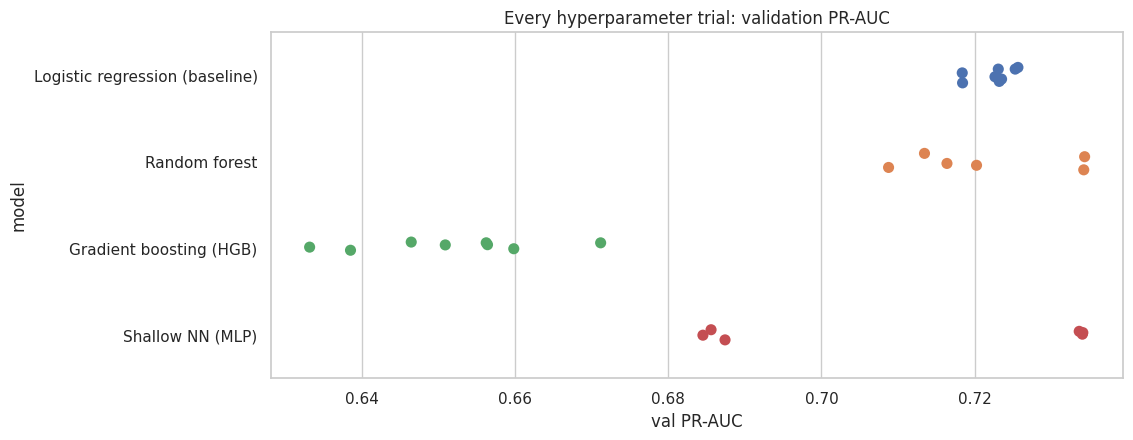

,model,params,val PR-AUC,val ROC-AUC,fit s
15,Gradient boosting (HGB),"{'lr': 0.03, 'leaves': 15, 'l2': 1.0}",0.6711,0.9258,0.6059
17,Gradient boosting (HGB),"{'lr': 0.03, 'leaves': 31, 'l2': 1.0}",0.6598,0.9261,0.8344
19,Gradient boosting (HGB),"{'lr': 0.1, 'leaves': 15, 'l2': 1.0}",0.6564,0.9253,0.2474
14,Gradient boosting (HGB),"{'lr': 0.03, 'leaves': 15, 'l2': 0.0}",0.6562,0.9248,0.5333
16,Gradient boosting (HGB),"{'lr': 0.03, 'leaves': 31, 'l2': 0.0}",0.6508,0.9240,0.9490
21,Gradient boosting (HGB),"{'lr': 0.1, 'leaves': 31, 'l2': 1.0}",0.6464,0.9258,0.3276
20,Gradient boosting (HGB),"{'lr': 0.1, 'leaves': 31, 'l2': 0.0}",0.6385,0.9217,0.3239
18,Gradient boosting (HGB),"{'lr': 0.1, 'leaves': 15, 'l2': 0.0}",0.6331,0.9194,0.2778
6,Logistic regression (baseline),"{'C': 10, 'cw': None}",0.7257,0.9343,0.7241
4,Logistic regression (baseline),"{'C': 1, 'cw': None}",0.7253,0.9340,0.7730


In [33]:
CANDIDATES = {
    "Logistic regression (baseline)": (
        lambda C, cw: Pipeline(make_pre() + [("m", LogisticRegression(max_iter=3000, C=C, class_weight=cw))]),
        [dict(C=C, cw=cw) for C in [0.01, 0.1, 1, 10] for cw in [None, "balanced"]]),
    "Random forest": (
        lambda depth, leaf: Pipeline(make_pre(scale=False) + [("m", RandomForestClassifier(
            n_estimators=300, max_depth=depth, min_samples_leaf=leaf, class_weight="balanced_subsample",
            n_jobs=-1, random_state=SEED))]),
        [dict(depth=d, leaf=l) for d in [6, 12, None] for l in [5, 25]]),
    "Gradient boosting (HGB)": (
        lambda lr, leaves, l2: HistGradientBoostingClassifier(
            learning_rate=lr, max_leaf_nodes=leaves, l2_regularization=l2, max_iter=400, early_stopping=True,
            validation_fraction=0.1, n_iter_no_change=20, random_state=SEED),
        [dict(lr=lr, leaves=lv, l2=l2) for lr in [0.03, 0.1] for lv in [15, 31] for l2 in [0.0, 1.0]]),
    "Shallow NN (MLP)": (
        lambda hidden, alpha: Pipeline(make_pre() + [("m", MLPClassifier(
            hidden_layer_sizes=hidden, alpha=alpha, activation="relu", solver="adam", learning_rate_init=1e-3,
            max_iter=300, early_stopping=True, validation_fraction=0.1, n_iter_no_change=15,
            random_state=SEED))]),
        [dict(hidden=h, alpha=a) for h in [(32,), (64, 32)] for a in [1e-4, 1e-3, 1e-2]]),
}
trials, best = [], {}
for name, (factory, grid) in CANDIDATES.items():
    for params in grid:
        t0 = time.time()
        model = factory(**params).fit(Xtr, ytr)
        pv = model.predict_proba(Xva)[:, 1]
        rec = {"model": name, "params": str(params), "val PR-AUC": average_precision_score(yva, pv),
               "val ROC-AUC": roc_auc_score(yva, pv), "fit s": time.time() - t0}
        trials.append(rec)
        if name not in best or rec["val PR-AUC"] > best[name]["val PR-AUC"]:
            best[name] = {**rec, "model_obj": model, "params_dict": params}
trials = savetable(pd.DataFrame(trials), "hyperparameter_trials")
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.stripplot(data=trials, y="model", x="val PR-AUC", size=8, ax=ax, hue="model", legend=False)
ax.set_title("Every hyperparameter trial: validation PR-AUC")
savefig(fig, "hyperparameter_trials", "All modelling attempts (hyperparameter variants per model family).")
trials.sort_values(["model", "val PR-AUC"], ascending=[True, False]).round(4)

### 8.3 Model comparison (threshold chosen on validation; test scored once)

In [34]:
rows, probs = [], {}
grid_score = lambda frame: -frame.grid_pos.to_numpy()
for split_name, frame, y in [("train", trn, ytr), ("validation", val, yva), ("test", tst, yte)]:
    p = grid_score(frame)
    yhat = (frame.grid_pos <= 3).astype(int)
    rows.append({"model": "Grid rule (reference)", "split": split_name, "ROC-AUC": roc_auc_score(y, p),
                 "PR-AUC": average_precision_score(y, p), "F1": f1_score(y, yhat),
                 "Precision": precision_score(y, yhat), "Recall": recall_score(y, yhat),
                 "Top-3 hit": top3_hit_rate(frame, p), "threshold": np.nan})
THRESHOLDS = {}
for name, b in best.items():
    model = b["model_obj"]
    pv = model.predict_proba(Xva)[:, 1]
    thr = best_threshold(yva, pv)
    THRESHOLDS[name] = thr
    for split_name, frame, X, y in [("train", trn, Xtr, ytr), ("validation", val, Xva, yva), ("test", tst, Xte, yte)]:
        p = model.predict_proba(X)[:, 1]
        probs[(name, split_name)] = p
        rows.append({"model": name, "split": split_name, **metrics(y, p, thr), "Top-3 hit": top3_hit_rate(frame, p),
                     "threshold": thr})
comparison = pd.DataFrame(rows)
savetable(comparison, "model_comparison")
BEST_NAME = max(best, key=lambda n: best[n]["val PR-AUC"])
BEST_MODEL, BEST_THR = best[BEST_NAME]["model_obj"], THRESHOLDS[BEST_NAME]
REPORT["best_model"] = BEST_NAME
REPORT["best_params"] = best[BEST_NAME]["params"]
print(f"Selected model (highest validation PR-AUC): {BEST_NAME} {best[BEST_NAME]['params']}, threshold {BEST_THR:.3f}")
comparison_wide = comparison.pivot(index="model", columns="split",
                                   values=["PR-AUC", "ROC-AUC", "F1", "Precision", "Recall", "Top-3 hit"])
comparison_wide = comparison_wide.reindex(columns=["train", "validation", "test"], level=1)
comparison_wide.round(3)

Selected model (highest validation PR-AUC): Random forest {'depth': None, 'leaf': 25}, threshold 0.735


PR-AUC                   ROC-AUC                       F1                   Precision                   Recall                   Top-3 hit  \
split                           train validation   test   train validation   test  train validation   test     train validation   test  train validation   test     train   
model                                                                                                                                                                       
Gradient boosting (HGB)         0.708      0.671  0.707   0.941      0.926  0.936  0.661      0.710  0.668     0.574      0.680  0.602  0.777      0.744  0.750     0.644   
Grid rule (reference)           0.539      0.639  0.647   0.898      0.909  0.914  0.582      0.692  0.649     0.583      0.692  0.650  0.581      0.692  0.647     0.584   
Logistic regression (baseline)  0.614      0.726  0.715   0.917      0.934  0.937  0.620      0.706  0.677     0.523      0.659  0.566  0.761      0.761  0.843     0.587   
Random forest                   0.704      0.734  0.710   0.944      0.933  0.939  0.658      0.706  0.673     0.609      0.703  0.631  0.714      0.709  0.721     0.638   
Shallow NN (MLP)                0.621      0.734  0.709   0.918      0.927  0.936  0.616      0.700  0.645     0.559      0.683  0.624  0.686      0.718  0.667     0.594   

                                                  
split                          validation   test  
model                                             
Gradient boosting (HGB)             0.675  0.637  
Grid rule (reference)               0.692  0.652  
Logistic regression (baseline)      0.701  0.657  
Random forest                       0.709  0.667  
Shallow NN (MLP)                    0.709  0.652

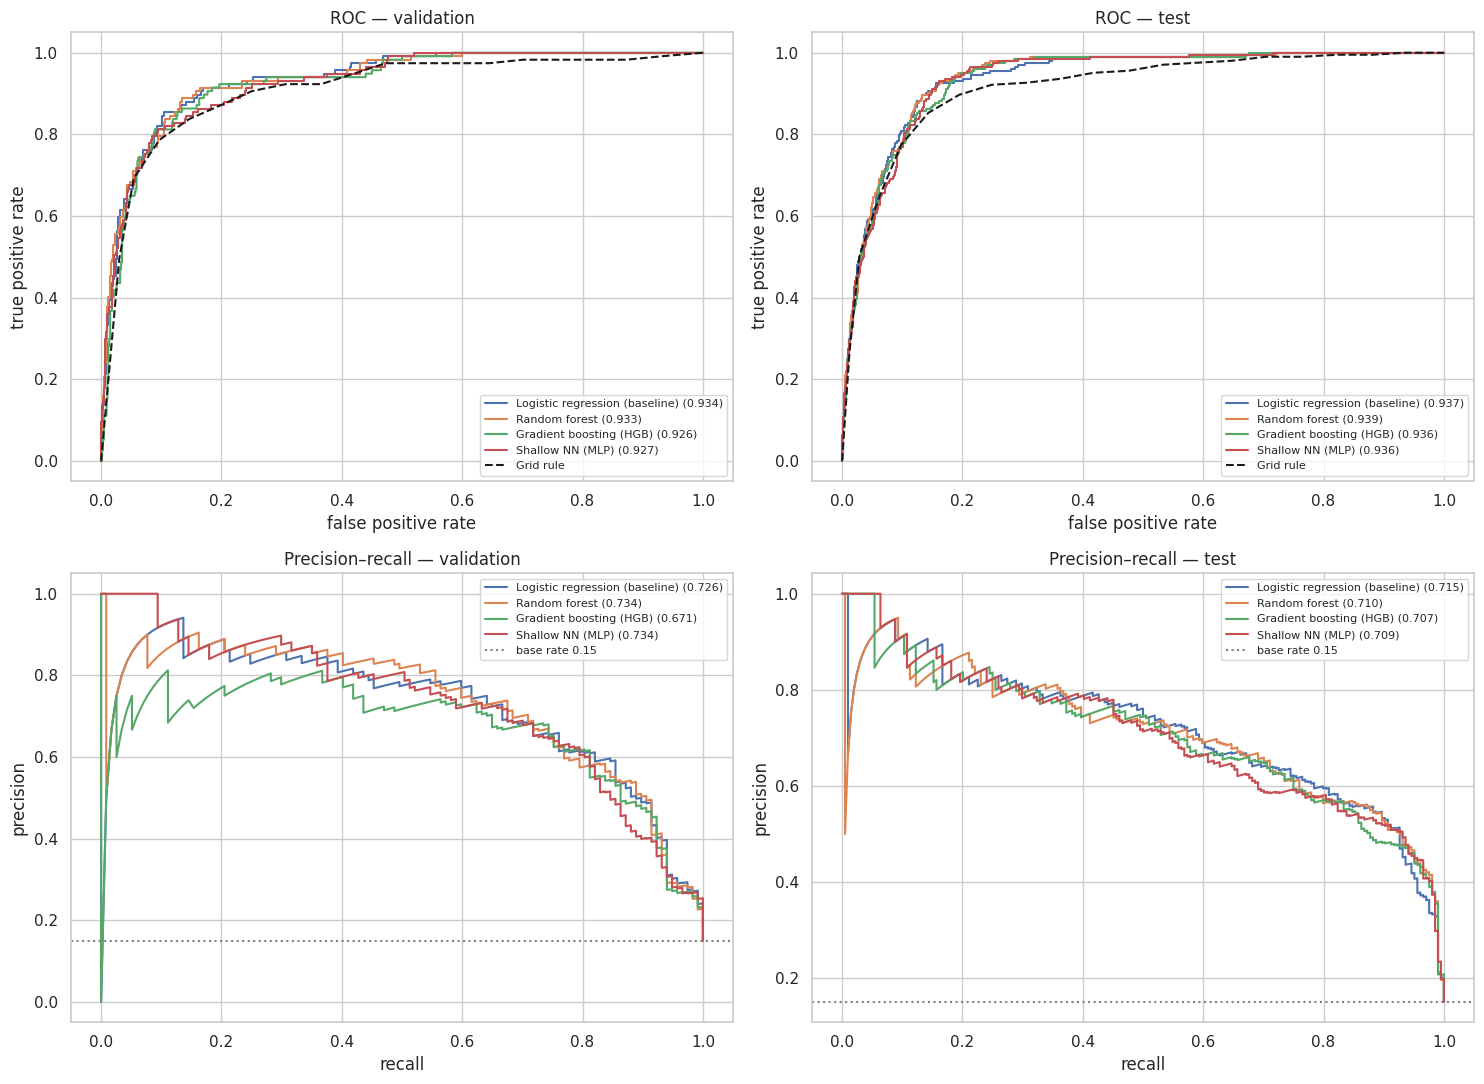

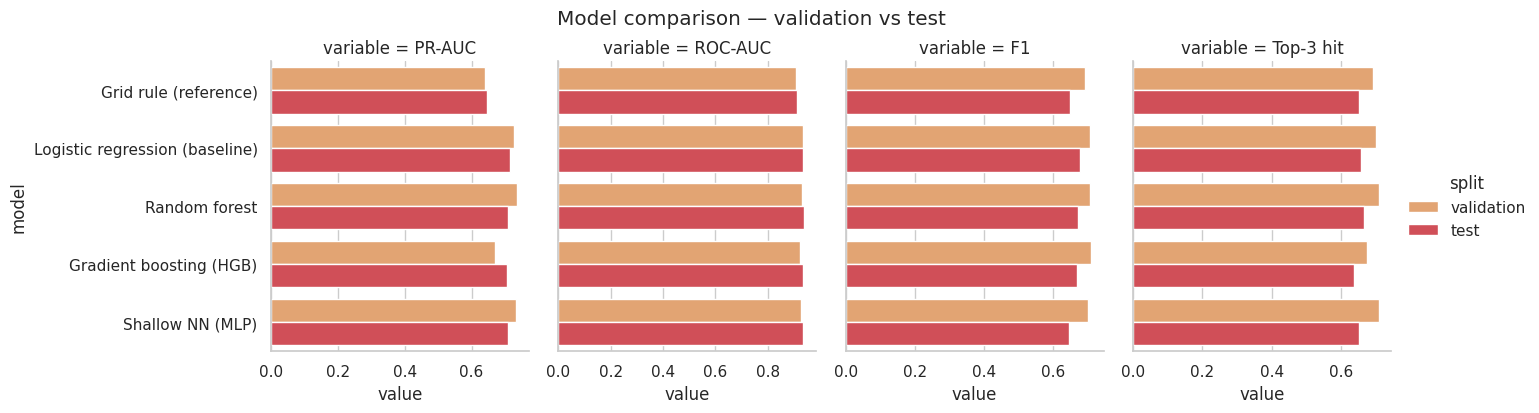

In [35]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
for col, split_name, y in [(0, "validation", yva), (1, "test", yte)]:
    for name in best:
        p = probs[(name, split_name)]
        fpr, tpr, _ = roc_curve(y, p)
        prec, rec, _ = precision_recall_curve(y, p)
        axes[0, col].plot(fpr, tpr, label=f"{name} ({roc_auc_score(y, p):.3f})")
        axes[1, col].plot(rec, prec, label=f"{name} ({average_precision_score(y, p):.3f})")
    frame = val if split_name == "validation" else tst
    fpr, tpr, _ = roc_curve(y, grid_score(frame))
    axes[0, col].plot(fpr, tpr, "k--", label="Grid rule")
    axes[0, col].set_title(f"ROC — {split_name}")
    axes[0, col].set_xlabel("false positive rate"); axes[0, col].set_ylabel("true positive rate")
    axes[1, col].axhline(y.mean(), color="grey", ls=":", label=f"base rate {y.mean():.2f}")
    axes[1, col].set_title(f"Precision–recall — {split_name}")
    axes[1, col].set_xlabel("recall"); axes[1, col].set_ylabel("precision")
    for ax in axes[:, col]:
        ax.legend(fontsize=8)
fig.tight_layout()
savefig(fig, "model_curves", "ROC and precision-recall curves on validation and test seasons.")

metric_plot = comparison[comparison.split.isin(["validation", "test"])].melt(
    id_vars=["model", "split"], value_vars=["PR-AUC", "ROC-AUC", "F1", "Top-3 hit"])
g = sns.catplot(data=metric_plot, x="value", y="model", hue="split", col="variable", kind="bar", height=4,
                aspect=0.9, sharex=False, palette=["#f4a261", "#e63946"])
g.figure.suptitle("Model comparison — validation vs test", y=1.03)
savefig(g.figure, "model_comparison", "Model comparison on validation and test.")

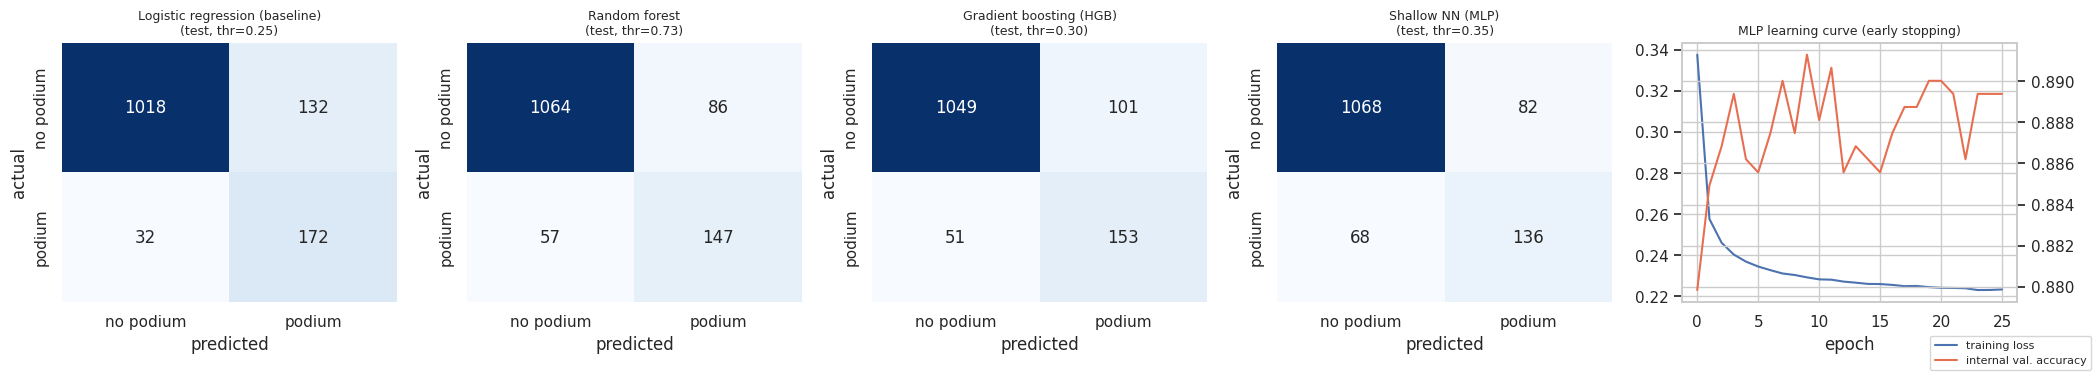

In [36]:
fig, axes = plt.subplots(1, len(best) + 1, figsize=(4.2 * (len(best) + 1), 3.8))
for ax, name in zip(axes, best):
    cm = confusion_matrix(yte, (probs[(name, "test")] >= THRESHOLDS[name]).astype(int))
    sns.heatmap(cm, annot=True, fmt="d", cbar=False, ax=ax, cmap="Blues",
                xticklabels=["no podium", "podium"], yticklabels=["no podium", "podium"])
    ax.set_title(f"{name}\n(test, thr={THRESHOLDS[name]:.2f})", fontsize=9)
    ax.set_xlabel("predicted"); ax.set_ylabel("actual")
mlp = best["Shallow NN (MLP)"]["model_obj"].named_steps["m"]
axes[-1].plot(mlp.loss_curve_, label="training loss")
ax2 = axes[-1].twinx()
ax2.plot(mlp.validation_scores_, color="#e76f51", label="internal val. accuracy")
axes[-1].set_title("MLP learning curve (early stopping)", fontsize=9)
axes[-1].set_xlabel("epoch")
fig.legend(loc="lower right", fontsize=8)
fig.tight_layout()
savefig(fig, "confusion_and_mlp", "Confusion matrices on the test seasons and the MLP training curve.")

**Model choice vs the baseline.** The random forest (no depth limit, at least 25 rows per leaf, threshold 0.735)
has the highest validation PR-AUC (0.734) and is selected by our rule. It is clearly better than the simple
"first three on the grid" rule (test PR-AUC 0.710 vs 0.647; test top-3 hit 66.7% vs 65.2%). **But it does not
clearly beat the logistic-regression baseline:** the baseline scores 0.726 on validation and is slightly better on
test (PR-AUC 0.715, F1 0.677 vs 0.710 and 0.673). With only 779 validation rows these differences are within
noise. The shallow MLP ties the forest on validation (0.734) and the two-layer version (64, 32) is worse than the
one-layer version (32), so more depth did not help. Gradient boosting is the weakest model here (val PR-AUC
0.671) and its top-3 hit rate is even below the grid rule. **Conclusion:** most of the predictive signal is
captured by a linear model on well-built pre-race features; the extra complexity adds little.

Train PR-AUC is lower than validation PR-AUC for the linear model and the MLP (0.614 vs 0.726). This is not
leakage: the validation seasons are simply easier to predict. Even the plain grid rule scores PR-AUC 0.539 on the
training seasons (1980–2019) but 0.639 on 2020–2021, so the gap comes from the seasons, not from the model.

*Numbers from the full Kaggle run (Version 1, 17 Oct 2026). Re-check them if the code or data change.*

**How the models work and their limitations**

| model | how it works | limitations here |
|---|---|---|
| Logistic regression | weighted sum of standardised features → sigmoid | only linear effects in each feature (no grid × team interaction unless engineered) |
| Random forest | many deep trees on bootstrap samples, averaged votes | probabilities poorly calibrated; cannot extrapolate beyond training ranges |
| Gradient boosting | trees added one by one, each fixing the previous errors | easy to overfit without early stopping; sensitive to era drift |
| Shallow MLP | 1–2 layers of ReLU units trained with Adam, L2 penalty, early stopping | needs scaling, less interpretable, results vary with the random seed |

Shared limitations: one prediction per driver independently (the model does not know a race has exactly three
podium places — the *top-3 hit rate* evaluates this view); regulation changes (2022) shift the relationship
between past form and results; qualifying features are missing before the mid-1990s.

## 9. Feature-group ablation
Remove one group at a time, re-train the selected model type with its chosen hyperparameters (and the baseline),
re-tune the threshold on validation, and measure the change.

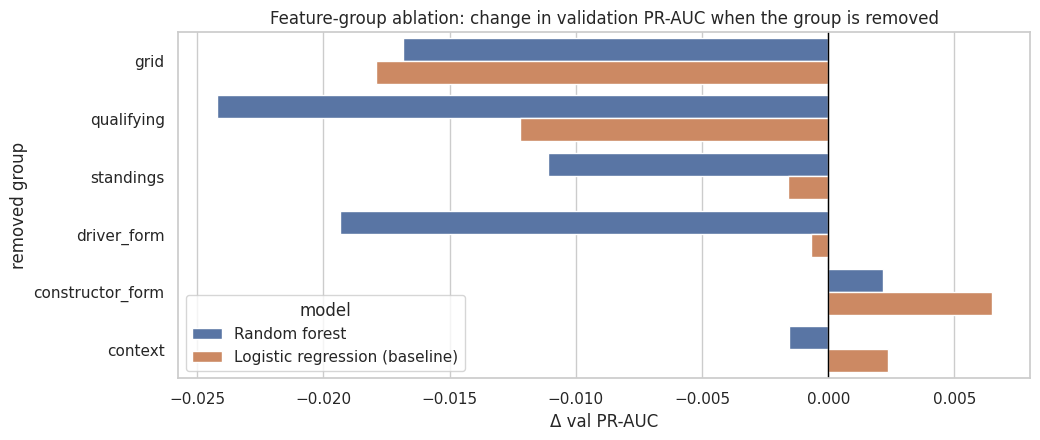

,model,removed group,n features,val PR-AUC,Δ val PR-AUC,test PR-AUC,Δ test PR-AUC,val F1,test F1
0,Random forest,— none (full model),24,0.7344,0.0000,0.7096,0.0000,0.7064,0.6728
1,Random forest,grid,21,0.7175,-0.0168,0.6762,-0.0334,0.7100,0.6205
2,Random forest,qualifying,21,0.7101,-0.0242,0.7190,0.0094,0.6964,0.6548
3,Random forest,standings,17,0.7233,-0.0111,0.7066,-0.0030,0.7162,0.6788
4,Random forest,driver_form,17,0.7150,-0.0194,0.7090,-0.0006,0.7094,0.6603
5,Random forest,constructor_form,21,0.7365,0.0022,0.7096,0.0000,0.7100,0.6667
6,Random forest,context,23,0.7328,-0.0016,0.7103,0.0007,0.7069,0.6682
7,Logistic regression (baseline),— none (full model),24,0.7257,0.0000,0.7148,0.0000,0.7063,0.6772
8,Logistic regression (baseline),grid,21,0.7077,-0.0179,0.6896,-0.0251,0.6964,0.6016
9,Logistic regression (baseline),qualifying,21,0.7135,-0.0122,0.7130,-0.0017,0.7049,0.6765


In [37]:
abl_rows = []
for model_name in dict.fromkeys([BEST_NAME, "Logistic regression (baseline)"]):
    factory = CANDIDATES[model_name][0]
    params = best[model_name]["params_dict"]
    for removed in [None] + list(GROUPS):
        feats = [f for f in FEATURES if removed is None or f not in GROUPS[removed]]
        m = factory(**params).fit(trn[feats].astype(float), ytr)
        pv = m.predict_proba(val[feats].astype(float))[:, 1]
        pt = m.predict_proba(tst[feats].astype(float))[:, 1]
        thr = best_threshold(yva, pv)
        abl_rows.append({"model": model_name, "removed group": removed or "— none (full model)",
                         "n features": len(feats), **{f"val {k}": v for k, v in metrics(yva, pv, thr).items()},
                         **{f"test {k}": v for k, v in metrics(yte, pt, thr).items()}})
ablation = pd.DataFrame(abl_rows)
for mname, g in ablation.groupby("model"):
    full = g[g["removed group"].str.startswith("—")].iloc[0]
    ablation.loc[g.index, "Δ val PR-AUC"] = g["val PR-AUC"] - full["val PR-AUC"]
    ablation.loc[g.index, "Δ test PR-AUC"] = g["test PR-AUC"] - full["test PR-AUC"]
savetable(ablation, "ablation")
fig, ax = plt.subplots(figsize=(11, 4.5))
plot_ab = ablation[~ablation["removed group"].str.startswith("—")]
sns.barplot(data=plot_ab, y="removed group", x="Δ val PR-AUC", hue="model", ax=ax)
ax.axvline(0, color="black", lw=1)
ax.set_title("Feature-group ablation: change in validation PR-AUC when the group is removed")
savefig(fig, "ablation", "Feature-group ablation: negative = the group was contributing.")
ablation[["model", "removed group", "n features", "val PR-AUC", "Δ val PR-AUC", "test PR-AUC", "Δ test PR-AUC",
          "val F1", "test F1"]].round(4)

**Ablation — interpretation.** For the random forest, removing the **grid** group gives the largest drop on the
test seasons (PR-AUC −0.033, F1 0.673 → 0.621), and removing **qualifying** gives the largest drop on validation
(−0.024). Removing driver form (−0.019) and standings (−0.011) also hurts on validation. Removing constructor form
(+0.002) or context (−0.002) changes almost nothing, because their information is already carried by standings and
driver form. For the logistic-regression baseline, the grid group matters most on both validation (−0.018) and
test (−0.025). So starting position is the group the models cannot do without.

*Numbers from the full Kaggle run (Version 1, 17 Oct 2026). Re-check them if the code or data change.*

## 10. Explainability (XAI)

> **Not causal.** Importance and SHAP values describe *what the model relies on* to make predictions, not what
> causes podium finishes. For example, a high importance for constructor points means teams that scored well
> recently tend to score well again — the points do not cause the result; the underlying car performance drives
> both.

### 10.1 Global: permutation importance (validation seasons, scored with PR-AUC)

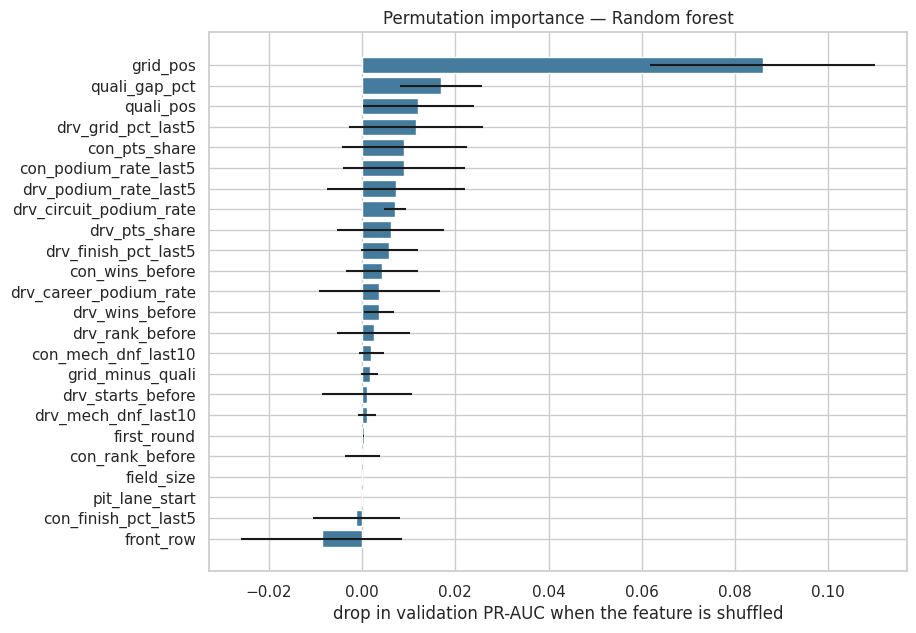

,feature,mean,std
0,grid_pos,0.0859,0.0241
4,quali_gap_pct,0.0169,0.0087
3,quali_pos,0.0121,0.0120
15,drv_grid_pct_last5,0.0116,0.0143
9,con_pts_share,0.0091,0.0134
20,con_podium_rate_last5,0.0090,0.0132
13,drv_podium_rate_last5,0.0072,0.0148
19,drv_circuit_podium_rate,0.0071,0.0024
6,drv_pts_share,0.0061,0.0115
14,drv_finish_pct_last5,0.0058,0.0061


In [38]:
pi = permutation_importance(BEST_MODEL, Xva, yva, scoring="average_precision", n_repeats=10, random_state=SEED,
                            n_jobs=-1)
pi_df = pd.DataFrame({"feature": FEATURES, "mean": pi.importances_mean, "std": pi.importances_std}) \
    .sort_values("mean", ascending=False)
savetable(pi_df, "permutation_importance")
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(pi_df.feature, pi_df["mean"], xerr=pi_df["std"], color="#457b9d")
ax.invert_yaxis()
ax.set_xlabel("drop in validation PR-AUC when the feature is shuffled")
ax.set_title(f"Permutation importance — {BEST_NAME}")
savefig(fig, "xai_permutation_importance", "Permutation importance on the validation seasons.")
REPORT["pi_top"] = pi_df.head(5).feature.tolist()
pi_df.round(4)

**Permutation importance — interpretation.** Shuffling `grid_pos` lowers validation PR-AUC by **0.086**, far more
than any other feature. Next come `quali_gap_pct` (0.017), `quali_pos` (0.012), `drv_grid_pct_last5` (0.012) and
`con_pts_share` (0.009). Apart from `grid_pos`, the error bars are as large as the values (only 779 validation
rows), so the order below the top feature should not be over-read. Correlated features share importance: grid and
qualifying position carry similar information, so shuffling one of them costs little while the other is still
there (`front_row` even comes out slightly negative).

*Numbers from the full Kaggle run (Version 1, 17 Oct 2026). Re-check them if the code or data change.*

### 10.2 Global: SHAP

PermutationExplainer explainer: 501it [08:11,  1.01it/s]


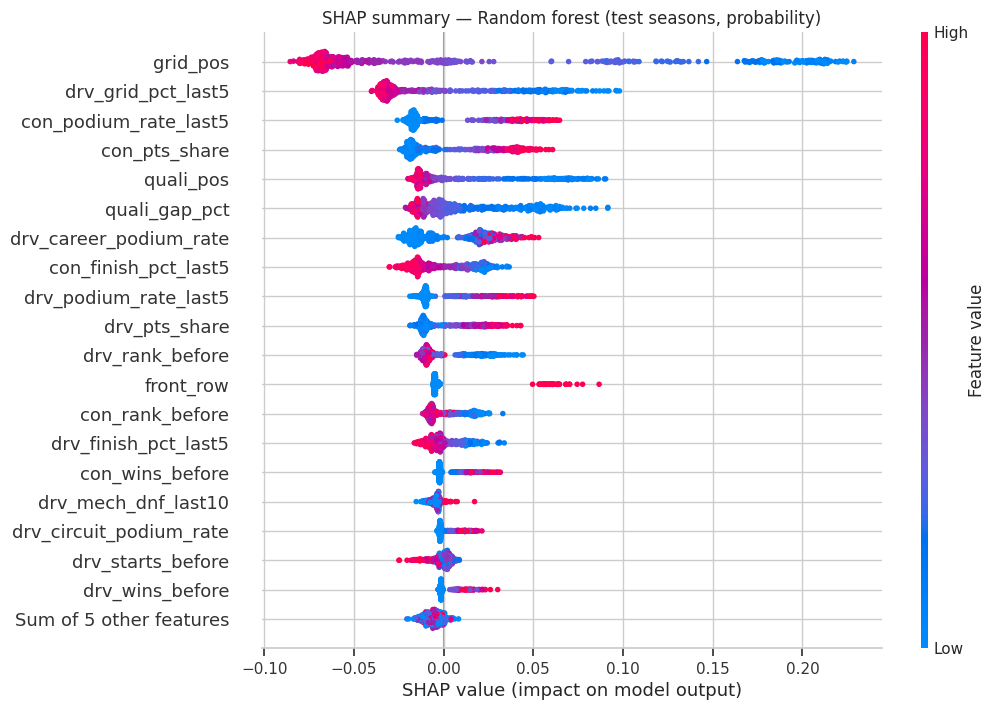

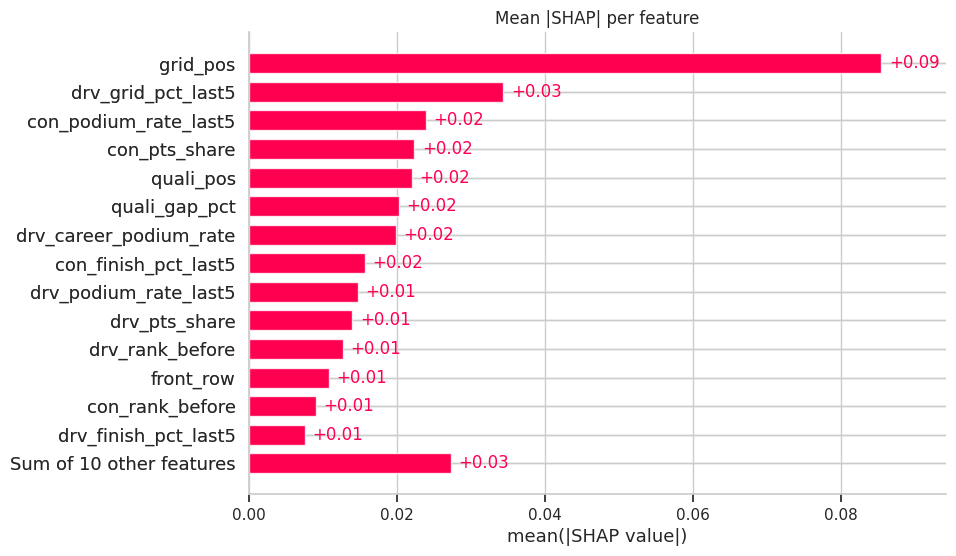

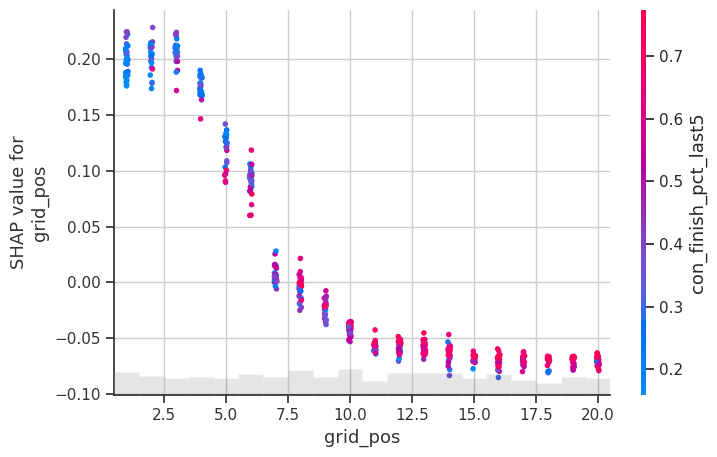

In [39]:
def predict_pos(X):
    X = pd.DataFrame(np.asarray(X, dtype=float), columns=FEATURES)
    return BEST_MODEL.predict_proba(X)[:, 1]


shap_values = None
if HAS_SHAP:
    sample_te = Xte.sample(min(500, len(Xte)), random_state=SEED)
    if isinstance(BEST_MODEL, HistGradientBoostingClassifier):
        explainer = shap.TreeExplainer(BEST_MODEL)
        shap_values = explainer(sample_te)
        shap_units = "log-odds"
    else:
        background = shap.sample(Xtr.fillna(Xtr.median()), 100, random_state=SEED)
        explainer = shap.Explainer(predict_pos, background, feature_names=FEATURES)
        shap_values = explainer(sample_te.fillna(Xtr.median()))
        shap_units = "probability"
    shap.plots.beeswarm(shap_values, max_display=20, show=False)
    fig = plt.gcf()
    fig.set_size_inches(10, 8)
    plt.title(f"SHAP summary — {BEST_NAME} (test seasons, {shap_units})")
    savefig(fig, "xai_shap_beeswarm", "SHAP beeswarm: each dot is one driver-race; colour is the feature value.")
    shap.plots.bar(shap_values, max_display=15, show=False)
    fig = plt.gcf()
    fig.set_size_inches(9, 6)
    plt.title("Mean |SHAP| per feature")
    savefig(fig, "xai_shap_bar", "Mean absolute SHAP value per feature.")
    top_feat = pd.Series(np.abs(shap_values.values).mean(0), index=FEATURES).sort_values(ascending=False)
    REPORT["shap_top"] = top_feat.head(5).index.tolist()
    if "grid_pos" in FEATURES:
        shap.plots.scatter(shap_values[:, "grid_pos"], color=shap_values, show=False)
        fig = plt.gcf()
        fig.set_size_inches(8, 5)
        savefig(fig, "xai_shap_dependence_grid", "SHAP dependence of grid position, coloured by its strongest "
                "interaction.")
else:
    print("SHAP is not installed — run `pip install shap` to produce these plots.")

**SHAP — interpretation.** SHAP agrees that **`grid_pos` dominates** (mean |SHAP| ≈ 0.09, about three times the
next feature). The dependence plot shows the shape: starting P1–P3 adds about +0.2 to the podium probability,
the effect falls steeply between P4 and P10, and from P10 back it is flat at about −0.06. Next are
`drv_grid_pct_last5` (where the driver usually started in the last 5 races), then team form
(`con_podium_rate_last5`, `con_pts_share`) and `quali_pos`. In the beeswarm, low grid and high team form push
predictions up, as expected. The model therefore relies mostly on **where the car starts and how strong the car
has been recently**.

**Not causal.** These values describe what the model *relies on*, not what *causes* a podium. A fast car causes
both a good grid slot and a podium; the grid slot itself is a signal of car pace, not the reason for the result.

*Numbers from the full Kaggle run (Version 1, 17 Oct 2026). Re-check them if the code or data change.*

### 10.3 Local explanations: one correct podium call and one false alarm (test seasons)

true positive: Max Verstappen, 2023 Dutch Grand Prix — p(podium)=0.98, actual podium=True, grid=1
false positive: Max Verstappen, 2024 Australian Grand Prix — p(podium)=0.98, actual podium=False, grid=1


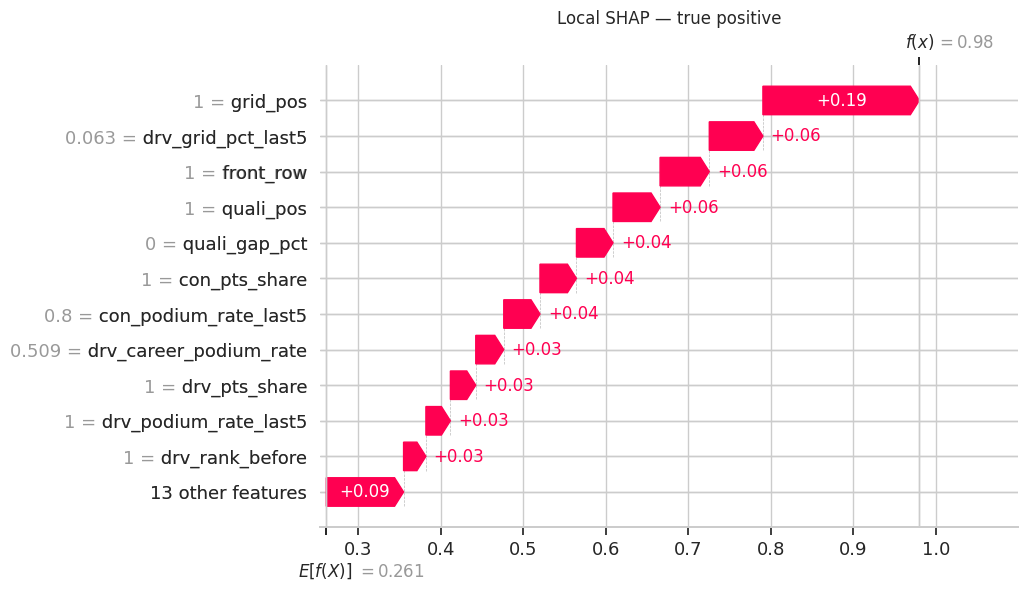

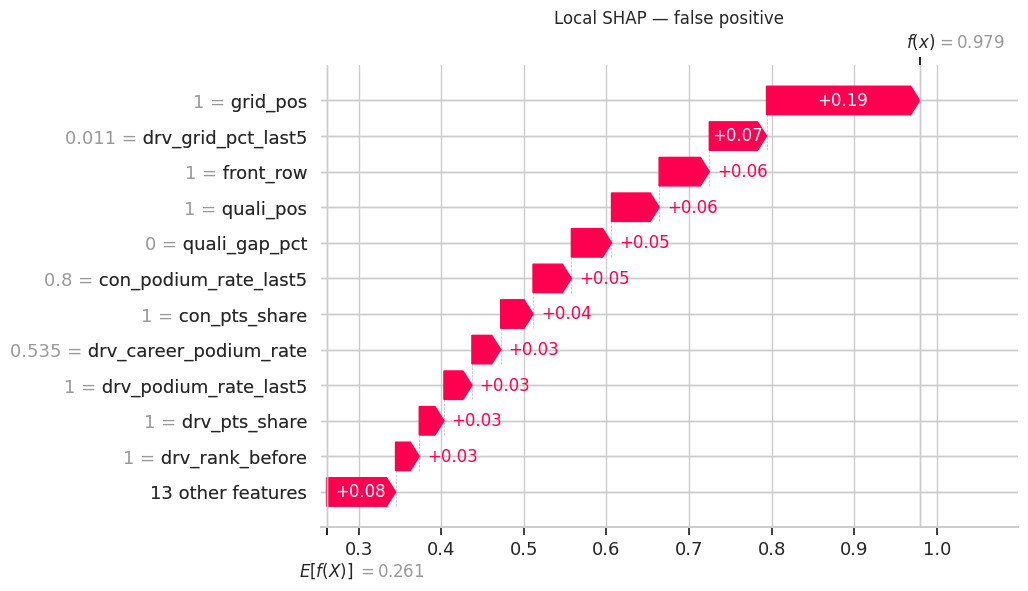

In [40]:
p_test = BEST_MODEL.predict_proba(Xte)[:, 1]
tst_view = tst.assign(p=p_test).reset_index(drop=True).merge(
    clean["drivers"][["driverId", "forename", "surname"]], on="driverId", how="left")   # 'name' = race name
tp_i = int(tst_view[(tst_view.podium == 1)].p.idxmax())
fp_cands = tst_view[(tst_view.podium == 0) & (tst_view.p >= BEST_THR)]
fp_i = int(fp_cands.p.idxmax()) if len(fp_cands) else int(tst_view[tst_view.podium == 0].p.idxmax())
local_cases = {"true positive": tp_i, "false positive": fp_i}
for label, i in local_cases.items():
    rw = tst_view.loc[i]
    print(f"{label}: {rw.forename} {rw.surname}, {rw.year} {rw['name']} — p(podium)={rw.p:.2f}, "
          f"actual podium={bool(rw.podium)}, grid={rw.grid_pos:.0f}")

if shap_values is not None:
    for label, i in local_cases.items():
        x_row = Xte.iloc[[i]] if isinstance(BEST_MODEL, HistGradientBoostingClassifier) \
            else Xte.iloc[[i]].fillna(Xtr.median())
        sv = explainer(x_row)
        shap.plots.waterfall(sv[0], max_display=12, show=False)
        fig = plt.gcf()
        fig.set_size_inches(9, 6)
        plt.title(f"Local SHAP — {label}")
        savefig(fig, f"xai_local_shap_{label.replace(' ', '_')}", f"SHAP waterfall for one {label} prediction.")

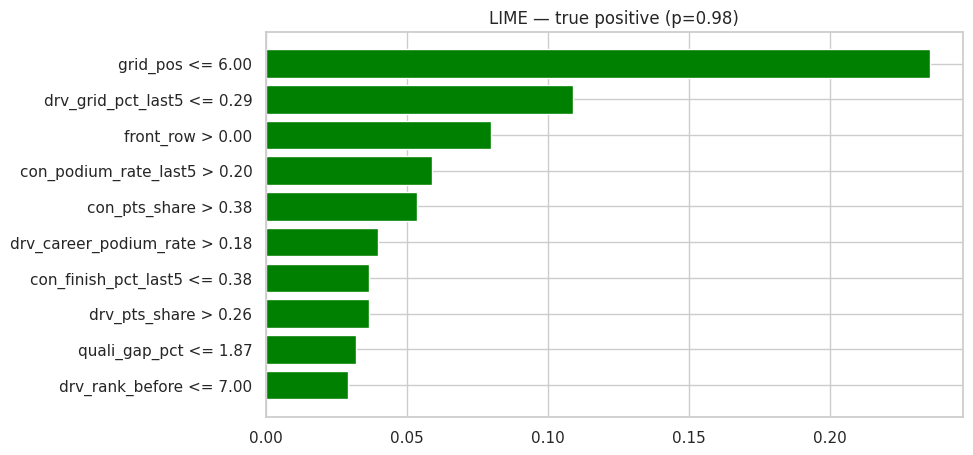

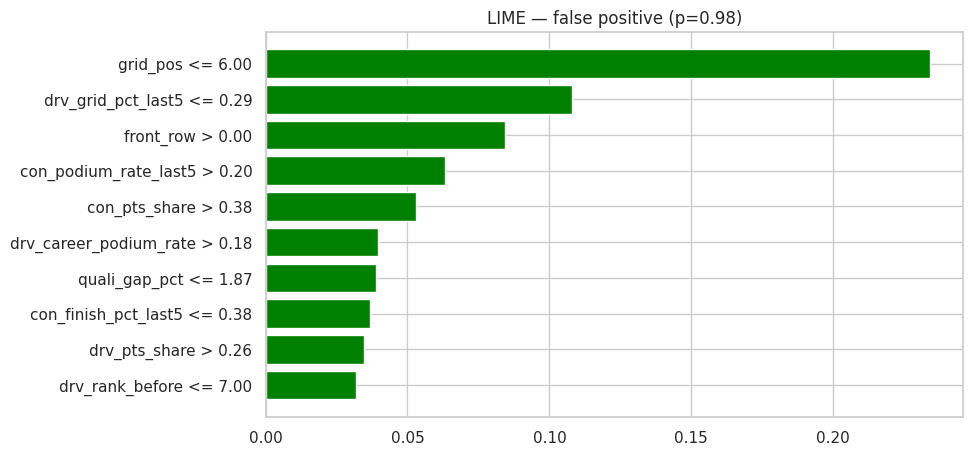

In [41]:
def lime_predict(X):
    p = predict_pos(X)
    return np.column_stack([1 - p, p])


if HAS_LIME:
    med = Xtr.median()
    lime_exp = LimeTabularExplainer(Xtr.fillna(med).to_numpy(), feature_names=FEATURES,
                                    class_names=["no podium", "podium"], mode="classification",
                                    discretize_continuous=True, random_state=SEED)
    for label, i in local_cases.items():
        exp = lime_exp.explain_instance(Xte.iloc[i].fillna(med).to_numpy(), lime_predict, num_features=10)
        fig = exp.as_pyplot_figure()
        fig.set_size_inches(9, 5)
        plt.title(f"LIME — {label} (p={p_test[i]:.2f})")
        savefig(fig, f"xai_lime_{label.replace(' ', '_')}", f"LIME explanation for one {label} prediction.")
else:
    print("LIME is not installed — local explanation shown with SHAP only (`pip install lime` to add it).")

**Local explanations — interpretation.** Both examples are Max Verstappen starting from pole with p(podium) =
0.98. In the **true positive** (2023 Dutch GP) and the **false alarm** (2024 Australian GP) the SHAP waterfalls
and LIME bars look almost the same: grid P1 (about +0.19 in SHAP), strong recent grid positions, front row and
qualifying P1 push the prediction up, and no feature pushes it down. This shows a key limitation: the model only
sees pre-race information, so it cannot foresee race events such as a retirement. A confident wrong prediction for
a pole sitter is expected from time to time and is not a sign of a bug. LIME and local SHAP agree on the top
features, which gives us more trust in the explanation.

*Numbers from the full Kaggle run (Version 1, 17 Oct 2026). Re-check them if the code or data change.*

## 11. Inference function
`predict_podium(record)` accepts a dict of pre-race features. Missing or unknown values are allowed: missing ones
are handled by the model (native NaN handling for gradient boosting, train-median imputation + missing indicators
for the pipelines); unknown keys are reported and ignored.

In [42]:
def predict_podium(record, model=None, threshold=None):
    model = model or BEST_MODEL
    threshold = BEST_THR if threshold is None else threshold
    unknown = sorted(set(record) - set(FEATURES))
    rec = {f: record.get(f, np.nan) for f in FEATURES}
    if pd.isna(rec.get("grid_pct", 0)) and not pd.isna(rec.get("grid_pos", np.nan)) \
            and not pd.isna(rec.get("field_size", np.nan)) and "grid_pct" in FEATURES:
        rec["grid_pct"] = (rec["grid_pos"] - 1) / max(rec["field_size"] - 1, 1)
    if "front_row" in FEATURES and pd.isna(rec["front_row"]) and not pd.isna(rec.get("grid_pos", np.nan)):
        rec["front_row"] = int(rec["grid_pos"] <= 2)
    X = pd.DataFrame([rec], columns=FEATURES).astype(float)
    p = float(model.predict_proba(X)[0, 1])
    missing = [f for f in FEATURES if pd.isna(X.iloc[0][f])]
    return {"podium_probability": round(p, 4), "predicted_podium": bool(p >= threshold),
            "threshold": round(threshold, 4), "missing_features": missing, "ignored_keys": unknown}


complete_idx = Xte.dropna().index
complete_record = Xte.loc[complete_idx[0]].to_dict() if len(complete_idx) else Xte.iloc[0].to_dict()
print("Complete record →", predict_podium(complete_record))
partial_record = {"grid_pos": 2, "field_size": 20, "con_pts_share": 0.9, "drv_pts_share": 0.6,
                  "team_principal": "unknown"}
print("Partially-missing record →", predict_podium(partial_record))
REPORT["inference_complete"] = predict_podium(complete_record)
REPORT["inference_partial"] = predict_podium(partial_record)

Complete record → {'podium_probability': 0.8006, 'predicted_podium': True, 'threshold': 0.7346, 'missing_features': [], 'ignored_keys': []}
Partially-missing record → {'podium_probability': 0.575, 'predicted_podium': False, 'threshold': 0.7346, 'missing_features': ['pit_lane_start', 'quali_pos', 'quali_gap_pct', 'grid_minus_quali', 'drv_rank_before', 'drv_wins_before', 'con_rank_before', 'con_wins_before', 'first_round', 'drv_podium_rate_last5', 'drv_finish_pct_last5', 'drv_grid_pct_last5', 'drv_mech_dnf_last10', 'drv_career_podium_rate', 'drv_starts_before', 'drv_circuit_podium_rate', 'con_podium_rate_last5', 'con_finish_pct_last5', 'con_mech_dnf_last10'], 'ignored_keys': ['team_principal']}


## 12. Analytical report
Builds `outputs/report/report.html` (all figures embedded) and `report.md` from the numbers computed above.
Open the HTML in a browser and *Print → Save as PDF* for the submission. The team should still read it and add
its own interpretation where marked.

In [43]:
def fmt_pct(x):
    return "n/a" if x is None or (isinstance(x, float) and np.isnan(x)) else f"{100 * x:.1f}%"


best_val = comparison[(comparison.model == BEST_NAME) & (comparison.split == "validation")].iloc[0]
best_test = comparison[(comparison.model == BEST_NAME) & (comparison.split == "test")].iloc[0]
grid_test = comparison[(comparison.model == "Grid rule (reference)") & (comparison.split == "test")].iloc[0]
abl_best = ablation[(ablation.model == BEST_NAME) & ~ablation["removed group"].str.startswith("—")] \
    .sort_values("Δ val PR-AUC")
FEATURE_DOCS = {
    "grid": "starting position after penalties (grid_pos; pit-lane start = back of field + flag), its relative "
            "version grid_pct and front_row — fixed before lights out",
    "qualifying": "qualifying position, gap to pole in % of the pole lap, grid − qualifying (penalties) — "
                  "qualifying is complete at the cutoff; missing before ~1994 (indicator added)",
    "standings": "driver and constructor points share of the leader, rank and wins from the PREVIOUS round of "
                 "the same season — never this race's standings",
    "driver_form": "driver's podium rate, finish percentile and grid percentile over the last 5 races, "
                   "mechanical-DNF rate over 10, career podium rate, experience, past podium rate at this circuit "
                   "— all shift(1), only strictly earlier races",
    "constructor_form": "team podium rate and finish percentile over its last 5 races, mechanical-DNF rate over "
                        "10 — computed on the team's own time line, shift(1)",
    "context": "field size and home race — known from the entry list and calendar",
}
sections = [
    ("1. Data and cleaning", f"""
Raw results rows: {len(raw['results']):,}. After foreign-key reconciliation ({REPORT['fk_orphans']} orphans), the grain
fix ({REPORT['dup_pairs']} duplicated driver–race pairs from shared drives; rule: keep the car the driver started in,
{REPORT['dup_rows_removed']} rows removed; {REPORT['dup_label_diff']} podium labels would differ under the
best-finish rule) and the scope rules (Indianapolis 500 and non-starters excluded), the modelling table has
{REPORT['n_rows_model_base']:,} rows, one per (raceId, driverId). All `\\N` sentinels were converted to missing values;
dates, clock times and durations (lap, qualifying, pit-stop times → seconds) were typed and every conversion was
checked for parse failures. Qualifying data covers most rows only from {REPORT['first_quali_year']}.""",
     ["eda_raw_sentinels", "eda_raw_seasons", "eda_clean_impact", "eda_clean_distributions"]),
    ("2. Q1 — front-row conversion by circuit", f"""
Overall front-row (grid) conversion: {', '.join(f'{k}: {fmt_pct(v)}' for k, v in REPORT['q1_overall'].items())}.
Across the {REPORT['q1_n_circuits']} circuits with enough front-row starts in both periods, the Spearman rank
correlation between the two periods is ρ = {REPORT['q1_rho']:.2f} (p = {REPORT['q1_p']:.3f}).
Top-5 before 2014: {', '.join(REPORT['q1_top_pre'])}. Top-5 since 2014: {', '.join(REPORT['q1_top_post'])}.
Qualifying vs grid: {REPORT['q1_penalised']} drivers qualified on the front row but started further back (penalties);
they converted at {fmt_pct(REPORT['q1_pen_rate'])}. Grain: front-row starts (driver–race); missingness: the qualifying
definition only uses 1994+ rows; cutoff: both grid and qualifying are pre-race.""", ["q1_front_row_conversion"]),
    ("3. Q2 — home advantage, controlling for grid", f"""
Home starts: {REPORT['q2_n_home']:,} of {REPORT['q2_n']:,}. Crude podium rate home {fmt_pct(REPORT['q2_home_rate'])} vs
away {fmt_pct(REPORT['q2_away_rate'])} (crude OR {REPORT['q2_or_crude']:.2f}); home drivers start on average from
grid {REPORT['q2_home_grid']:.1f} vs {REPORT['q2_away_grid']:.1f}. Within grid bands, the Mantel–Haenszel odds ratio is
{REPORT['q2_or_mh']:.2f} (95% CI {REPORT['q2_ci'][0]:.2f}–{REPORT['q2_ci'][1]:.2f}, p = {REPORT['q2_p']:.3g}).
An OR whose CI includes 1 means no detectable home effect once starting position is accounted for.
Grain: race starts; missingness: nationalities without a mapped country are never "home"; Indianapolis 500
excluded.""", ["q2_home_advantage"]),
    ("4. Q3 — mechanical retirements", f"""
Overall mechanical-retirement rate per start: {', '.join(f'{k}: {fmt_pct(v)}' for k, v in REPORT['q3_overall'].items())}.
Highest rates: {'; '.join(f"{p}: " + ', '.join(f'{c} {fmt_pct(r)} ({n} starts)' for c, r, n in v)
                          for p, v in REPORT['q3_top'].items())}.
Mechanical = component failure (engine, gearbox, hydraulics, power unit, ERS, …); crashes, driver errors, punctures,
pit-crew errors and regulation decisions are excluded (full mapping in `tables/q3_status_mapping.csv`).
Constructor identity follows constructorId, so renamed teams (e.g. Toro Rosso → AlphaTauri → RB) appear
separately.""", ["q3_mechanical_retirements"]),
    ("5. Features and why each is valid at the cutoff",
     "<ul>" + "".join(f"<li><b>{g}</b>: {html.escape(FEATURE_DOCS[g])}. Used: {', '.join(fs)}</li>"
                      for g, fs in GROUPS.items()) + "</ul>"
     + (f"<p>Dropped by the evidence rule: {html.escape('; '.join(f'{k} ({v})' for k, v in REPORT['dropped_features'].items()))}.</p>"
        if REPORT["dropped_features"] else "")
     + f"<p>Leakage checks: the rolling-form brute-force test found 0 mismatches; adding this race's points gain "
       f"(leaky) moves validation PR-AUC from {leak_table['val PR-AUC'][0]:.3f} to {leak_table['val PR-AUC'][1]:.3f}.</p>",
     ["features_univariate_auc", "features_binned_rates", "features_correlation", "features_coverage_drift"]),
    ("6. Split, pre-processing and experiments", f"""
Temporal split: train {REPORT['train_from']}–{TRAIN_END} (training window chosen on validation PR-AUC), validation
{TRAIN_END + 1}–{VAL_END}, test {VAL_END + 1}–{int(df.year.max())}. Pre-processing order experiments (logistic
regression):<br>{order_exp[['val PR-AUC', 'test PR-AUC']].round(3).to_html()}""",
     ["split", "preprocessing_effect", "preprocessing_order"]),
    ("7. Models", f"""
Primary metric PR-AUC (rare positive class, ranking quality), secondary F1 at the validation-chosen threshold.
Selected model: <b>{BEST_NAME}</b> {html.escape(REPORT['best_params'])}: validation PR-AUC {best_val['PR-AUC']:.3f},
test PR-AUC {best_test['PR-AUC']:.3f}, test ROC-AUC {best_test['ROC-AUC']:.3f}, test F1 {best_test['F1']:.3f},
test top-3 hit rate {fmt_pct(best_test['Top-3 hit'])} (grid-rule reference: PR-AUC {grid_test['PR-AUC']:.3f},
top-3 {fmt_pct(grid_test['Top-3 hit'])}).<br>{comparison_wide.round(3).to_html()}""",
     ["hyperparameter_trials", "model_comparison", "model_curves", "confusion_and_mlp"]),
    ("8. Feature-group ablation", f"""
Largest validation PR-AUC drop when removed: {', '.join(f"{r['removed group']} ({r['Δ val PR-AUC']:+.3f})"
                                                       for _, r in abl_best.head(3).iterrows())}.<br>
{ablation[['model', 'removed group', 'val PR-AUC', 'Δ val PR-AUC', 'test PR-AUC', 'Δ test PR-AUC']].round(3).to_html(index=False)}""",
     ["ablation"]),
    ("9. Explainability", f"""
Permutation importance top-5: {', '.join(REPORT['pi_top'])}. SHAP top-5: {', '.join(REPORT.get('shap_top', ['n/a']))}.
<b>These are not causal effects</b>: they show what the model relies on, not what makes a driver finish on the podium.
Correlated features (e.g. grid and qualifying position) share importance, so one can look unimportant while the
pair is essential.""",
     [k for k in FIGURES if k.startswith("xai_")]),
    ("10. Inference", f"""Complete record: {html.escape(str(REPORT['inference_complete']))}<br>
Partially-missing record: {html.escape(str(REPORT['inference_partial']))}""", []),
    ("11. Known limitations", """
<ul><li>Historical qualifying-coverage drift: qualifying features are missing before the mid-1990s; they are imputed
with an indicator, so the model treats old and modern rows differently.</li>
<li>Era sensitivity: regulation changes (2014, 2022) reshuffle competitiveness; form features adapt only after a few
races, so early-season predictions after a rule change are weakest.</li>
<li>Constructor identity breaks at renames; team history resets.</li>
<li>Independent per-driver predictions ignore that each race has exactly three podium places.</li>
<li>Sprint results and practice data are not used; weather and safety cars are not in the data.</li>
<li>Small samples for some circuits and constructors in Q1/Q3 — see the confidence intervals.</li></ul>""", []),
]


def img_tag(name):
    path, caption = FIGURES[name]
    b64 = base64.b64encode(Path(path).read_bytes()).decode()
    return (f'<figure><img src="data:image/png;base64,{b64}" style="max-width:100%"><figcaption>'
            f'{html.escape(caption)}</figcaption></figure>')


body = "".join(f"<h2>{html.escape(t)}</h2><p>{txt}</p>" + "".join(img_tag(n) for n in figs if n in FIGURES)
               for t, txt, figs in sections)
report_html = f"""<!doctype html><html><head><meta charset="utf-8"><title>F1 Podium Prediction — Milestone 1</title>
<style>body{{font-family:Georgia,serif;max-width:1000px;margin:auto;padding:24px;line-height:1.45}}
table{{border-collapse:collapse;font-size:12px}}td,th{{border:1px solid #ccc;padding:3px 6px}}
figcaption{{font-size:12px;color:#555}}h2{{border-bottom:2px solid #e63946;padding-bottom:4px;margin-top:36px}}
@media print{{figure{{page-break-inside:avoid}}}}</style></head><body>
<h1>Formula 1 Podium Prediction — Milestone 1 Report</h1>
<p>ACL · predicting whether a driver finishes in the top 3 using only information available after qualifying and
before the race.</p>{body}</body></html>"""
(REPORT_DIR / "report.html").write_text(report_html, encoding="utf-8")
md = "# Formula 1 Podium Prediction — Milestone 1 Report\n\n" + "\n\n".join(
    f"## {t}\n\n{re.sub(r'<[^>]+>', ' ', txt).strip()}\n\n" + "\n".join(
        f"![{FIGURES[n][1]}](../figures/{n}.png)" for n in figs if n in FIGURES) for t, txt, figs in sections)
(REPORT_DIR / "report.md").write_text(md, encoding="utf-8")
print("Report written to", (REPORT_DIR / "report.html").resolve())
print(f"{len(FIGURES)} figures in {FIG_DIR.resolve()}, tables in {TAB_DIR.resolve()}")

Report written to /kaggle/working/outputs/report/report.html
28 figures in /kaggle/working/outputs/figures, tables in /kaggle/working/outputs/tables
